<a href="https://colab.research.google.com/github/renatobacha/MVP-AnalisedeDadosPUCRIO/blob/main/MVP_Diabetes_Analise_Exploratoria_FINAL_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MVP – Análise de Dados e Boas Práticas
## Predição de Risco de Diabetes (Diabetes Risk Prediction Dataset – 50 mil pacientes)

**Autor:** Renato Bacha  
**Disciplina:** Análise de Dados e Boas Práticas  
**Fonte dos dados:** [Kaggle – Diabetes Risk Prediction Dataset (50K patients)](https://www.kaggle.com/datasets/mobeenfatimah/diabetes-risk-prediction-dataset-50k-patients)

---

### Roteiro do notebook
1. **Definição do problema** – descrição, tipo de aprendizado, hipóteses, restrições e dicionário de atributos
2. **Configuração e carga dos dados** – bibliotecas, parâmetros e leitura do CSV direto do GitHub
3. **Análise de dados** – estatísticas descritivas e visualizações (cada gráfico é seguido de uma análise)
4. **Pré-processamento** – limpeza, divisão treino/teste e quatro visões diferentes do dataset salvas em arquivo
5. **Conclusões** – resposta às hipóteses, pontos de atenção e próximos passos

## Resumo do trabalho (em linguagem simples)

**Objetivo:** preparar, para uma futura modelagem, um dataset de 50.000 pacientes cujo alvo é o **nível de risco de diabetes** (`Low`, `Moderate` ou `High`).

**O que encontramos:**
1. **Os dados parecem sintéticos** (gerados por computador): quase todos os atributos são uniformes, independentes entre si e com contradições clínicas, como pressão diastólica maior que a sistólica.
2. **A maioria dos pacientes é de risco alto:** 73,2% `High`, 25,9% `Moderate` e só 0,9% `Low`.
3. **Três colunas entregam a resposta** (pontuação de risco, recomendação da IA e indicação de consulta) e foram removidas para evitar vazamento de dados.
4. **Os atributos que mais se associam ao risco** são glicemia de jejum, HbA1c, histórico familiar, idade e IMC. Nenhum, sozinho, separa bem as classes.
5. **`Blood_Glucose` não tem relação com o risco**, apesar de ser uma medida de glicose.

**O que fizemos nos dados:** removemos colunas indevidas, preenchemos valores em branco, separamos treino e teste (80% / 20%, mantendo as proporções das classes) e geramos **quatro versões** do dataset (`onehot`, `padronizado`, `normalizado` e `discretizado`), salvas em `dados_processados/`.

## Glossário rápido

| Termo | O que significa |
|---|---|
| **Atributo / variável** | Uma coluna do dataset (por exemplo, idade ou glicose). |
| **Alvo** | O que queremos prever: o nível de risco (`Diabetes_Risk`). |
| **Dados sintéticos** | Dados gerados por computador, e não coletados de pessoas reais. |
| **Valor faltante (`NaN`)** | Célula em branco, sem informação. |
| **Imputação** | Preencher os valores em branco com um valor razoável (mediana para números, categoria mais comum para texto). |
| **Outlier** | Valor muito afastado dos demais. |
| **Correlação** | Número de -1 a +1 que mede se duas variáveis "andam juntas" (0 = sem relação em linha reta). |
| **Vazamento de dados** | Quando uma coluna já contém a resposta, fazendo o modelo parecer melhor do que realmente é. |
| **Desbalanceamento** | Quando uma classe tem muito mais exemplos que as outras. |
| **Estratificação** | Dividir treino e teste mantendo as mesmas proporções de cada classe. |
| **Padronização (z-score)** | Reescalar uma variável para ter média 0 e desvio 1. |
| **Normalização (min-max)** | Reescalar uma variável para o intervalo de 0 a 1. |
| **Discretização** | Transformar um número em faixas (por exemplo, 5 faixas de igual quantidade de pacientes). |
| ***One-hot encoding*** | Transformar cada categoria em uma coluna 0/1. |
| **p.p. (ponto percentual)** | Diferença entre duas porcentagens (de 64% para 83% são 19 p.p.). |

# 1. Definição do problema

### 1.1 Descrição do problema
O *diabetes mellitus* é uma doença crônica de alta prevalência mundial. Quando não é identificada cedo, aumenta o risco de complicações cardiovasculares, renais, oculares e neurológicas. Identificar pacientes com maior risco a partir de dados clínicos, de estilo de vida e demográficos permite priorizar exames e ações preventivas.

Este trabalho usa um dataset com **50.000 registros de pacientes** e **41 colunas** para **prever o nível de risco de diabetes** do paciente (variável alvo `Diabetes_Risk`). O escopo desta entrega vai **da definição do problema até o pré-processamento**: ao final teremos os dados limpos, sem colunas indevidas, divididos em treino e teste e transformados em diferentes versões prontas para a modelagem (que não faz parte deste MVP).

### 1.2 Tipo de aprendizado
**Aprendizado supervisionado – classificação.** Existe uma variável alvo rotulada (`Diabetes_Risk`) a ser prevista a partir das demais variáveis (*features*). No dataset, `Diabetes_Risk` possui **três classes ordenadas**: `Low` (risco baixo) < `Moderate` (risco moderado) < `High` (risco alto). Trata-se, portanto, de uma **classificação multiclasse com classes ordinais**.

### 1.3 Premissas e hipóteses
- **Premissa:** os registros representam adequadamente os pacientes e a variável alvo foi rotulada de forma consistente.
- **H1:** pacientes de risco mais alto têm **glicose** (`Blood_Glucose`, `Fasting_Blood_Sugar`) e **hemoglobina glicada** (`HbA1c`) mais elevadas.
- **H2:** pacientes de risco mais alto têm **IMC** (`BMI`) e **idade** (`Age`) maiores, em média.
- **H3:** pacientes com **histórico familiar** (`Family_History_Diabetes`) têm maior proporção na classe de maior risco.
- **H4:** níveis mais altos de **atividade física** (`Physical_Activity_Level`, `Exercise_Hours_Per_Week`) estão associados a uma proporção menor na classe de maior risco.

Essas hipóteses são confrontadas com os dados na seção 3 e revisitadas na seção 5.

### 1.4 Restrições e condições na seleção dos dados
- O dataset **não pode ser um dos utilizados em aula** (exigência do enunciado do MVP).
- Os dados ficam em um repositório público do GitHub e são lidos pelo URL *raw*, para que o notebook rode do início ao fim no Colab sem etapas manuais.
- Segundo a descrição do Kaggle, trata-se de um conjunto de **registros sintéticos** (*50K synthetic patient records*). Isso é uma limitação importante: relações clínicas conhecidas **podem não aparecer** nos dados. As conclusões valem para este dataset, não para pacientes reais.
- Para evitar **vazamento de dados** (*data leakage*), colunas que são identificadores ou que parecem derivadas do próprio risco **não entram como variáveis preditoras** (justificativa na seção 3.2).

### 1.5 Dicionário de atributos
> As descrições foram deduzidas dos nomes das colunas (as unidades não constam no CSV); as **faixas e categorias** abaixo foram **observadas no próprio dataset**. Total: 41 colunas (23 numéricas e 18 de texto).

| Atributo | Tipo | Descrição | Valores observados |
|---|---|---|---|
| `Patient_ID` | identificador | Número sequencial do paciente (**descartado**) | 1 a 50.000, sem repetição |
| `Age` | numérico | Idade, em anos | 18 a 90 |
| `Gender` | categórico | Sexo/gênero | Male, Female, Other |
| `Country` | categórico | País de residência | 25 países |
| `Height_cm` | numérico | Altura, em cm | 145 a 195 |
| `Weight_kg` | numérico | Peso, em kg | 45 a 130 |
| `BMI` | numérico | Índice de Massa Corporal (kg/m²), calculado a partir de peso e altura | 11,9 a 61,7 |
| `Waist_Circumference_cm` | numérico | Circunferência abdominal, em cm | 60 a 140 |
| `Blood_Glucose` | numérico | Glicose no sangue (mg/dL) | 70 a 250 |
| `HbA1c` | numérico | Hemoglobina glicada (%), reflete a glicemia média dos últimos meses | 4,5 a 12,5 |
| `Fasting_Blood_Sugar` | numérico | Glicemia em jejum (mg/dL) | 65 a 220 |
| `Insulin_Level` | numérico | Nível de insulina | 2 a 45 |
| `Blood_Pressure_Systolic` | numérico | Pressão arterial sistólica (mmHg) | 90 a 190 |
| `Blood_Pressure_Diastolic` | numérico | Pressão arterial diastólica (mmHg) | 60 a 120 |
| `Total_Cholesterol` | numérico | Colesterol total (mg/dL) | 120 a 320 |
| `HDL` | numérico | Colesterol HDL, o "bom" (mg/dL) | 25 a 90 |
| `LDL` | numérico | Colesterol LDL, o "ruim" (mg/dL) | 50 a 220 |
| `Triglycerides` | numérico | Triglicerídeos (mg/dL) | 60 a 400 |
| `Heart_Rate` | numérico | Frequência cardíaca (bpm) | 50 a 120 |
| `Physical_Activity_Level` | categórico ordinal | Nível de atividade física | Low, Moderate, High |
| `Exercise_Hours_Per_Week` | numérico | Horas de exercício por semana | 0 a 10 |
| `Daily_Walking_Minutes` | numérico | Minutos de caminhada por dia | 0 a 180 |
| `Diet_Quality` | categórico ordinal | Qualidade da dieta | Poor, Average, Healthy |
| `Sugar_Intake_Level` | categórico ordinal | Consumo de açúcar | Low, Moderate, High |
| `Sleep_Hours` | numérico | Horas de sono por dia | 3 a 10 |
| `Stress_Level` | categórico ordinal | Nível de estresse | Low, Moderate, High |
| `Smoking_Status` | categórico | Situação de tabagismo | Never, Former, Current |
| `Alcohol_Consumption` | categórico ordinal | Consumo de álcool | Never, Occasionally, Frequently |
| `Family_History_Diabetes` | categórico binário | Histórico familiar de diabetes | Yes, No |
| `Hypertension` | categórico binário | Presença de hipertensão | Yes, No |
| `Heart_Disease` | categórico binário | Presença de doença cardíaca | Yes, No |
| `Fatty_Liver` | categórico binário | Presença de esteatose hepática (gordura no fígado) | Yes, No |
| `PCOS` | categórico binário | Síndrome dos ovários policísticos | Yes, No |
| `Medication_Adherence` | categórico ordinal | Adesão à medicação | Poor, Average, Good |
| `Work_Type` | categórico | Tipo de ocupação | Business, Private, Government, Student, Retired |
| `Residence_Type` | categórico binário | Tipo de residência | Urban, Rural |
| `Daily_Water_Intake_L` | numérico | Consumo diário de água, em litros | 1 a 5 |
| `Diabetes_Risk_Score` | numérico | Pontuação de risco de diabetes (**descartada**: vazamento do alvo) | 13 a 100 |
| `AI_Health_Recommendation` | categórico | Recomendação de saúde gerada por IA (**descartada**: vazamento do alvo) | 15 recomendações |
| `Doctor_Consultation_Needed` | categórico binário | Indicação de consulta médica (**descartada**: vazamento do alvo) | Yes, No |
| `Diabetes_Risk` | categórico ordinal | **Variável alvo**: nível de risco de diabetes | Low, Moderate, High |

# 2. Configuração e carga dos dados

### 2.1 Bibliotecas
Usamos `pandas` e `numpy` para manipulação, `matplotlib` e `seaborn` para gráficos e `scikit-learn` para o pré-processamento.

In [1]:
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (KBinsDiscretizer, MinMaxScaler,
                                   OneHotEncoder, StandardScaler)

sns.set_theme(style="whitegrid")

### 2.2 Parâmetros do projeto
Todos os valores que podem mudar ficam concentrados nesta célula:
- `DATA_URL`: endereço *raw* do CSV no repositório público do GitHub;
- `TARGET`: coluna alvo;
- `CLASS_ORDER`: ordem das classes do menos para o mais grave. ordem das classes do menor para o maior risco: `Low` < `Moderate` < `High`. **É essencial informá-la**: sem ela, o código usa a ordem alfabética (High, Low, Moderate), o que inverte a leitura de "classe de maior risco" e das correlações com o alvo;
- `ID_COLS` e `LEAKAGE_COLS`: colunas que não entram como variáveis preditoras.

In [2]:
DATA_URL = ("https://raw.githubusercontent.com/renatobacha/"
            "MVP-AnalisedeDadosPUCRIO/main/"
            "diabetes_risk_prediction_dataset.csv")

TARGET = "Diabetes_Risk"                 # coluna alvo
CLASS_ORDER = ["Low", "Moderate", "High"]   # ordem crescente de risco (None = ordem alfabética)
ID_COLS = ["Patient_ID"]                 # identificadores (sem valor preditivo)
LEAKAGE_COLS = ["Diabetes_Risk_Score",   # colunas suspeitas de derivarem do alvo
                "AI_Health_Recommendation",
                "Doctor_Consultation_Needed"]

TEST_SIZE = 0.20                         # proporção reservada para teste
RANDOM_STATE = 42                        # reprodutibilidade
MAX_CATEGORIES_PLOT = 10                 # máximo de categorias exibidas por gráfico
OUTPUT_DIR = Path("dados_processados")   # pasta das visões do dataset

### 2.3 Carga dos dados e codificação do alvo
O CSV é lido diretamente do GitHub. A função **interrompe a execução com mensagem clara** se o arquivo não puder ser lido ou se a coluna alvo não existir. Não há dados de reserva: toda a análise vem exclusivamente do dataset real.

O alvo é recodificado para inteiros `0, 1, …` na ordem das classes (`CLASS_ORDER`), e o mapeamento é exibido.

In [3]:
def load_dataset(url: str, target: str) -> pd.DataFrame:
    """Lê o CSV a partir de uma URL e valida a presença da coluna alvo."""
    try:
        data = pd.read_csv(url)
    except Exception as error:
        raise RuntimeError(
            "Não foi possível ler o dataset. Confira se DATA_URL aponta para o "
            "arquivo *raw* de um repositório público do GitHub."
        ) from error

    if target not in data.columns:
        raise KeyError(f"Coluna alvo '{target}' não encontrada. "
                       f"Colunas disponíveis: {list(data.columns)}")
    return data


def encode_target(data: pd.DataFrame, target: str, class_order=None):
    """Recodifica o alvo para inteiros 0..k-1; devolve os dados e o dicionário {índice: rótulo}."""
    rows_before = len(data)
    data = data.dropna(subset=[target]).copy()
    if len(data) < rows_before:
        print(f"Linhas removidas por alvo ausente: {rows_before - len(data):,}")

    classes = list(class_order) if class_order else sorted(data[target].unique(), key=str)
    if not 2 <= len(classes) <= 10:
        raise ValueError(f"O alvo deveria ter de 2 a 10 classes, mas tem {len(classes)}: {classes[:12]}")

    mapping = {cls: idx for idx, cls in enumerate(classes)}
    unknown = set(data[target].unique()) - set(mapping)
    if unknown:
        raise ValueError(f"Valores do alvo fora de CLASS_ORDER: {unknown}")

    data[target] = data[target].map(mapping).astype(int)
    return data, {idx: str(cls) for cls, idx in mapping.items()}


df, CLASS_NAMES = encode_target(load_dataset(DATA_URL, TARGET), TARGET, CLASS_ORDER)
CLASS_LIST = list(CLASS_NAMES.values())     # rótulos na ordem das classes
N_CLASSES = len(CLASS_LIST)
HIGH_CLASS = CLASS_LIST[-1]                 # classe de maior risco
target_labels = df[TARGET].map(CLASS_NAMES).rename("classe")

print(f"Dataset carregado: {df.shape[0]:,} linhas x {df.shape[1]} colunas")
print(f"Alvo '{TARGET}': {N_CLASSES} classes -> {CLASS_NAMES}")
print("Tipo de problema:", "classificação binária" if N_CLASSES == 2 else "classificação multiclasse")

Dataset carregado: 50,000 linhas x 41 colunas
Alvo 'Diabetes_Risk': 3 classes -> {0: 'Low', 1: 'Moderate', 2: 'High'}
Tipo de problema: classificação multiclasse


# 3. Análise de dados

**Objetivo:** entender a informação disponível antes de transformá-la.

## 3.1 Estatísticas descritivas

### Dimensões, tipos de dados e primeiras linhas

In [4]:
print(f"Instâncias (linhas): {df.shape[0]:,}")
print(f"Atributos (colunas): {df.shape[1]} (sendo 1 o alvo)\n")
df.info()
pd.set_option("display.max_columns", None)
display(df.head(10))

Instâncias (linhas): 50,000
Atributos (colunas): 41 (sendo 1 o alvo)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 41 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Patient_ID                  50000 non-null  int64  
 1   Age                         49503 non-null  float64
 2   Gender                      50000 non-null  object 
 3   Country                     50000 non-null  object 
 4   Height_cm                   47055 non-null  float64
 5   Weight_kg                   47038 non-null  float64
 6   BMI                         50000 non-null  float64
 7   Waist_Circumference_cm      50000 non-null  float64
 8   Blood_Glucose               49041 non-null  float64
 9   HbA1c                       48026 non-null  float64
 10  Fasting_Blood_Sugar         50000 non-null  float64
 11  Insulin_Level               50000 non-null  float64
 12  Blood_Pressure_Sys

,Patient_ID,Age,Gender,Country,Height_cm,Weight_kg,BMI,Waist_Circumference_cm,Blood_Glucose,HbA1c,Fasting_Blood_Sugar,Insulin_Level,Blood_Pressure_Systolic,Blood_Pressure_Diastolic,Total_Cholesterol,HDL,LDL,Triglycerides,Heart_Rate,Physical_Activity_Level,Exercise_Hours_Per_Week,Daily_Walking_Minutes,Diet_Quality,Sugar_Intake_Level,Sleep_Hours,Stress_Level,Smoking_Status,Alcohol_Consumption,Family_History_Diabetes,Hypertension,Heart_Disease,Fatty_Liver,PCOS,Medication_Adherence,Work_Type,Residence_Type,Daily_Water_Intake_L,Diabetes_Risk_Score,AI_Health_Recommendation,Doctor_Consultation_Needed,Diabetes_Risk
0,1,32.0,Male,Mexico,182.1,65.8,19.8,71.2,88.4,10.4,149.5,27.4,94,61,138.7,40.1,152.3,250.8,119,Moderate,2.2,106.1,Healthy,Low,7.9,Moderate,Former,Never,Yes,No,Yes,Yes,No,Good,Retired,Rural,4.4,60,Healthy Diet Plan,Yes,1
1,2,42.0,Other,Saudi Arabia,148.5,101.2,45.9,121.8,247.3,11.3,199.3,18.3,148,100,286.8,35.6,110.4,287.9,59,High,6.3,96.1,Healthy,Low,6.2,Moderate,Current,Frequently,Yes,No,Yes,Yes,Yes,Average,Government,Rural,2.1,99,Begin Diabetes Management Plan,Yes,2
2,3,89.0,Other,Argentina,158.1,NaN,37.9,131.8,141.9,6.3,219.6,23.9,101,108,129.4,32.1,156.7,329.3,104,High,0.6,68.7,Average,High,4.8,High,Never,Frequently,Yes,No,No,Yes,No,Average,Government,Urban,2.8,80,Strict Blood Sugar Monitoring,Yes,2
3,4,87.0,Other,United States,190.9,95.9,26.3,99.1,90.1,7.4,217.7,36.7,120,63,168.2,61.9,63.4,308.8,58,High,7.7,23.1,Average,High,4.2,High,Current,Occasionally,Yes,Yes,No,No,No,Average,Business,Rural,1.5,82,Begin Diabetes Management Plan,Yes,2
4,5,27.0,Other,Australia,156.9,101.9,41.4,77.1,93.8,12.0,153.5,22.3,190,90,281.5,37.4,66.5,206.6,104,Moderate,4.7,131.2,Poor,High,9.9,Low,Never,Occasionally,No,Yes,Yes,Yes,Yes,Poor,Private,Rural,1.6,93,Begin Diabetes Management Plan,Yes,2
5,6,29.0,Male,Bangladesh,153.3,86.3,36.7,77.1,142.2,5.0,123.7,44.4,123,119,276.8,54.6,121.9,385.5,112,Low,1.9,39.2,Healthy,High,8.2,Low,Current,Occasionally,Yes,Yes,No,Yes,Yes,Poor,Retired,Urban,4.4,69,Consult Endocrinologist Immediately,Yes,2
6,7,90.0,Other,Germany,160.8,67.2,26.0,113.6,126.6,6.6,85.3,29.8,148,80,305.8,85.8,51.6,271.2,62,Low,5.4,91.1,Healthy,Moderate,9.2,Low,Former,Occasionally,Yes,No,No,Yes,No,Poor,Retired,Urban,4.8,68,Begin Diabetes Management Plan,Yes,2
7,8,80.0,Female,Bangladesh,190.3,116.9,32.3,67.4,146.2,6.7,65.5,35.2,171,76,152.3,NaN,170.0,250.7,64,Low,9.5,124.4,Healthy,High,3.3,Moderate,Current,Frequently,Yes,No,Yes,Yes,No,Average,Government,Urban,4.6,80,Begin Diabetes Management Plan,Yes,2
8,9,40.0,Female,United States,146.2,107.6,50.3,86.6,237.5,10.9,198.9,36.9,124,70,277.5,32.0,198.3,351.9,78,Low,8.2,82.9,Average,Low,4.6,High,Never,Occasionally,No,No,Yes,No,No,Poor,Business,Rural,3.7,79,Medical Evaluation Required,Yes,2
9,10,73.0,Other,Malaysia,194.2,54.8,14.5,132.0,104.2,4.9,132.6,24.4,158,103,263.9,73.2,164.0,183.8,58,High,9.2,112.2,Poor,Low,8.0,Moderate,Current,Occasionally,No,No,No,No,Yes,Good,Business,Rural,3.7,63,Weight Management Program,Yes,1


### Análise das primeiras linhas e dos tipos de dados

**Tamanho do dataset:** 50.000 pacientes (linhas) e 41 colunas: 40 candidatas a variáveis explicativas e 1 alvo, `Diabetes_Risk`.

**Tipos de dados:** 23 colunas são numéricas (medidas como idade, peso e glicose) e 18 são de texto, todas categóricas (níveis como `Low/Moderate/High`, respostas `Yes/No`, país etc.). O alvo vem em texto e foi convertido em números (Low = 0, Moderate = 1, High = 2) para poder ser analisado.

**O que chama a atenção nas primeiras linhas:**
1. **`Patient_ID`** é só um contador (1, 2, 3…). Não descreve o paciente e não ajuda a prever risco.
2. **Três colunas parecem *resultado* do risco, e não causa dele:** `Diabetes_Risk_Score` (pontuação), `AI_Health_Recommendation` (recomendação) e `Doctor_Consultation_Needed` (precisa de consulta). Elas são tratadas na seção 3.2.
3. **Há valores em branco (`NaN`)**, por exemplo, o peso do paciente 3 e o HDL do paciente 8.
4. **Há contradições clínicas.** O paciente 3 tem pressão diastólica (108) maior que a sistólica (101), o que não é possível. O paciente 1 tem LDL (152,3) maior que o colesterol total (138,7) e glicose de 88,4 mg/dL junto com HbA1c de 10,4%, valores que não combinam.
5. **`Gender` tem três categorias**, e `Other` aparece em cerca de um terço dos registros, proporção bem acima da realidade.
6. **`BMI` é calculado a partir de peso e altura** (paciente 1: 65,8 kg e 1,821 m dão 19,8), ou seja, repete informação que já existe.

**Em uma frase:** a base está organizada, mas tem sinais claros de ser artificial (sintética), e isso vai influenciar a leitura de todos os resultados.

### Valores faltantes, duplicados e inconsistências
Verificamos: (i) valores ausentes por coluna; (ii) linhas duplicadas; (iii) categorias com grafias diferentes para o mesmo valor.

In [5]:
missing = df.isna().sum().rename("ausentes").to_frame()
missing["% do total"] = (missing["ausentes"] / len(df) * 100).round(2)
display(missing[missing["ausentes"] > 0] if missing["ausentes"].any() else
        Markdown("**Nenhuma coluna possui valores ausentes.**"))

print(f"Linhas duplicadas: {df.duplicated().sum():,}")
print(f"Patient_ID duplicados: {df['Patient_ID'].duplicated().sum():,}" if "Patient_ID" in df.columns else "")

print("\nCategorias das colunas de texto (até 10 valores mais frequentes):")
for col in df.select_dtypes(include=["object", "category"]).columns:
    top_values = df[col].value_counts().head(10)
    print(f"  {col} ({df[col].nunique()} categorias): {top_values.to_dict()}")

,ausentes,% do total
Age,497,0.99
Height_cm,2945,5.89
Weight_kg,2962,5.92
Blood_Glucose,959,1.92
HbA1c,1974,3.95
Total_Cholesterol,1000,2.00
HDL,1000,2.00
LDL,1000,2.00
Triglycerides,1000,2.00
Physical_Activity_Level,500,1.00


Linhas duplicadas: 0
Patient_ID duplicados: 0

Categorias das colunas de texto (até 10 valores mais frequentes):
  Gender (3 categorias): {'Male': 16718, 'Other': 16677, 'Female': 16605}
  Country (25 categorias): {'Malaysia': 2083, 'Russia': 2071, 'France': 2068, 'China': 2065, 'Canada': 2050, 'United Kingdom': 2037, 'Nigeria': 2023, 'Indonesia': 2011, 'Egypt': 2010, 'Spain': 2007}
  Physical_Activity_Level (3 categorias): {'Low': 16693, 'High': 16502, 'Moderate': 16305}
  Diet_Quality (3 categorias): {'Healthy': 16882, 'Average': 16644, 'Poor': 16474}
  Sugar_Intake_Level (3 categorias): {'Low': 16864, 'Moderate': 16698, 'High': 16438}
  Stress_Level (3 categorias): {'Low': 16725, 'High': 16674, 'Moderate': 16601}
  Smoking_Status (3 categorias): {'Former': 16729, 'Current': 16693, 'Never': 16578}
  Alcohol_Consumption (3 categorias): {'Never': 16712, 'Occasionally': 16682, 'Frequently': 16606}
  Family_History_Diabetes (2 categorias): {'No': 25076, 'Yes': 24924}
  Hypertension (2 ca

### Consistência clínica entre atributos
Além de ausentes e duplicados, verificamos se os valores **fazem sentido entre si**. Foram testadas quatro regras simples:
1. a pressão **diastólica** não pode ser maior que a **sistólica**;
2. **LDL + HDL** não podem superar o **colesterol total**;
3. o **IMC** deve coincidir (tolerância de 0,5) com *peso ÷ altura²*;
4. glicose no sangue abaixo de 100 mg/dL é incompatível com **HbA1c ≥ 6,5%** (patamar de diabetes).

In [6]:
def count_rule(mask: pd.Series, valid: pd.Series) -> dict:
    """Conta violações de uma regra entre as linhas em que ela pode ser avaliada."""
    return {"linhas avaliadas": int(valid.sum()), "violações": int((mask & valid).sum()),
            "% das avaliadas": round((mask & valid).sum() / valid.sum() * 100, 2)}


bmi_calculated = df["Weight_kg"] / (df["Height_cm"] / 100) ** 2

consistency = pd.DataFrame({
    "PA diastólica > sistólica":
        count_rule(df["Blood_Pressure_Diastolic"] > df["Blood_Pressure_Systolic"], df["Blood_Pressure_Systolic"].notna()),
    "LDL + HDL > colesterol total":
        count_rule(df["LDL"] + df["HDL"] > df["Total_Cholesterol"],
                   df[["LDL", "HDL", "Total_Cholesterol"]].notna().all(axis=1)),
    "IMC diferente de peso/altura² (> 0,5)":
        count_rule((df["BMI"] - bmi_calculated).abs() > 0.5, bmi_calculated.notna()),
    "Glicose < 100 com HbA1c >= 6,5":
        count_rule((df["Blood_Glucose"] < 100) & (df["HbA1c"] >= 6.5),
                   df[["Blood_Glucose", "HbA1c"]].notna().all(axis=1)),
}).T
display(consistency)

,linhas avaliadas,violações,% das avaliadas
PA diastólica > sistólica,50000.0,3754.0,7.51
LDL + HDL > colesterol total,47050.0,17266.0,36.70
"IMC diferente de peso/altura² (> 0,5)",44259.0,0.0,0.00
"Glicose < 100 com HbA1c >= 6,5",47108.0,5896.0,12.52


### Análise das verificações de consistência

Testamos se os valores fazem sentido **entre si**. O resultado:

| Regra | Registros avaliados | Violações | % |
|---|---|---|---|
| Pressão diastólica maior que a sistólica | 50.000 | 3.754 | 7,5% |
| LDL + HDL maiores que o colesterol total | 47.050 | 17.266 | 36,7% |
| IMC diferente de peso ÷ altura² | 44.259 | 0 | 0,0% |
| Glicose < 100 com HbA1c ≥ 6,5% | 47.108 | 5.896 | 12,5% |

**O que isso significa:**
- O **IMC está sempre correto** em relação ao peso e à altura, ou seja, é uma coluna calculada e repete informação (o que será importante na análise de correlação).
- As outras três regras são violadas com frequência: 7,5% dos pacientes têm pressão impossível, mais de um terço tem colesterol incoerente e 1 em cada 8 tem glicose "normal" com HbA1c na faixa de diabetes.
- Isso indica que as colunas foram **sorteadas separadamente**, sem respeitar a lógica clínica. É coerente com a informação do Kaggle de que os dados são sintéticos.

**Decisão:** manter esses registros. Não dá para saber qual dos valores está errado, e remover todos eliminaria uma parte grande da base. O ponto fica registrado como limitação na seção 5.

**Em uma frase:** os dados têm contradições clínicas frequentes, típicas de dados gerados artificialmente.

## 3.2 Colunas que não entram como variáveis preditoras

- **`Patient_ID`** só identifica o paciente e não tem relação com o risco.
- **`Diabetes_Risk_Score`**, **`AI_Health_Recommendation`** e **`Doctor_Consultation_Needed`** parecem **consequências** ou **derivações** do risco, não causas. Se entrassem como preditoras, o modelo "descobriria" a resposta usando a própria resposta (*data leakage*) e teria um desempenho irreal.

A célula abaixo mostra a relação dessas colunas com o alvo como evidência. Se alguma **não** estiver fortemente ligada ao alvo, reavalie a decisão e remova-a de `LEAKAGE_COLS`.

In [7]:
def show_leakage_evidence(data: pd.DataFrame, columns, max_rows: int = 15) -> None:
    """Mostra como cada coluna suspeita se distribui entre as classes do alvo."""
    for col in columns:
        display(Markdown(f"**{col}** – tipo `{data[col].dtype}`, {data[col].nunique():,} valores distintos"))
        if pd.api.types.is_numeric_dtype(data[col]) and data[col].nunique() > 10:
            table = data.groupby(target_labels)[col].agg(["mean", "min", "max"]).reindex(CLASS_LIST)
        else:
            top = data[col].value_counts().index[:max_rows]
            subset = data[data[col].isin(top)]
            table = pd.crosstab(subset[col], target_labels.loc[subset.index],
                                normalize="index").reindex(columns=CLASS_LIST)
        display(table.round(3))


EXCLUDED_COLS = [col for col in ID_COLS + LEAKAGE_COLS if col in df.columns]
show_leakage_evidence(df, [col for col in LEAKAGE_COLS if col in df.columns])

df = df.drop(columns=EXCLUDED_COLS)
print(f"Colunas removidas das variáveis preditoras: {EXCLUDED_COLS}")
print(f"Restam {df.shape[1]} colunas (incluindo o alvo).")

**Diabetes_Risk_Score** – tipo `int64`, 86 valores distintos

,mean,min,max
classe,,,
Low,29.236,13,34
Moderate,54.839,35,64
High,81.409,65,100


**AI_Health_Recommendation** – tipo `object`, 15 valores distintos

classe,Low,Moderate,High
AI_Health_Recommendation,,,
Annual Diabetes Screening,1.0,0.0,0.0
Balanced Diet,1.0,0.0,0.0
Begin Diabetes Management Plan,0.0,0.0,1.0
Consult Endocrinologist Immediately,0.0,0.0,1.0
Exercise Regularly,1.0,0.0,0.0
Healthy Diet Plan,0.0,1.0,0.0
Immediate Lifestyle Intervention,0.0,0.0,1.0
Increase Physical Activity,0.0,1.0,0.0
Maintain Healthy Lifestyle,1.0,0.0,0.0


**Doctor_Consultation_Needed** – tipo `object`, 2 valores distintos

classe,Low,Moderate,High
Doctor_Consultation_Needed,,,
No,0.117,0.883,0.000
Yes,0.001,0.211,0.788


Colunas removidas das variáveis preditoras: ['Patient_ID', 'Diabetes_Risk_Score', 'AI_Health_Recommendation', 'Doctor_Consultation_Needed']
Restam 37 colunas (incluindo o alvo).


### Análise da evidência de vazamento

*Vazamento de dados* acontece quando uma coluna já "entrega" a resposta. O modelo parece ótimo, mas só porque está colando, e não funcionaria com um paciente novo. Veja o que as tabelas mostram:

- **`Diabetes_Risk_Score` (pontuação):** as faixas das classes **não se sobrepõem**. `Low` vai de 13 a 34, `Moderate` de 35 a 64 e `High` de 65 a 100. Ou seja, o alvo é simplesmente a pontuação dividida em três faixas.
- **`AI_Health_Recommendation` (recomendação):** cada uma das 15 recomendações aparece em **uma única classe**, cinco para cada nível de risco. Por exemplo, "Begin Diabetes Management Plan" ocorre 100% em `High`, "Healthy Diet Plan" 100% em `Moderate` e "Routine Health Checkup" 100% em `Low`. A recomendação só existe *depois* que o risco é conhecido.
- **`Doctor_Consultation_Needed` (precisa de consulta):** é quase determinística. Entre quem *não* precisa de consulta, 88,3% são `Moderate`, 11,7% são `Low` e nenhum é `High`. Entre quem precisa, 78,8% são `High`.

**Decisão:** remover as três colunas e também o `Patient_ID`. Sobram 36 variáveis explicativas mais o alvo.

**Em uma frase:** manter essas colunas daria um resultado falso, então elas foram retiradas.

In [8]:
def split_columns(data: pd.DataFrame, target: str):
    """Separa as colunas em contínuas, binárias numéricas e categóricas (texto)."""
    features = data.drop(columns=[target])
    categorical = features.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    numeric = features.select_dtypes(include="number").columns.tolist()
    binary = [col for col in numeric if features[col].nunique(dropna=True) <= 2]
    continuous = [col for col in numeric if col not in binary]
    return continuous, binary, categorical


continuous_cols, binary_cols, categorical_cols = split_columns(df, TARGET)
category_like_cols = categorical_cols + binary_cols   # tratadas como "categorias" nos gráficos

print(f"Contínuas  ({len(continuous_cols)}):", continuous_cols)
print(f"Binárias   ({len(binary_cols)}):", binary_cols)
print(f"Categóricas({len(categorical_cols)}):", categorical_cols)

Contínuas  (20): ['Age', 'Height_cm', 'Weight_kg', 'BMI', 'Waist_Circumference_cm', 'Blood_Glucose', 'HbA1c', 'Fasting_Blood_Sugar', 'Insulin_Level', 'Blood_Pressure_Systolic', 'Blood_Pressure_Diastolic', 'Total_Cholesterol', 'HDL', 'LDL', 'Triglycerides', 'Heart_Rate', 'Exercise_Hours_Per_Week', 'Daily_Walking_Minutes', 'Sleep_Hours', 'Daily_Water_Intake_L']
Binárias   (0): []
Categóricas(16): ['Gender', 'Country', 'Physical_Activity_Level', 'Diet_Quality', 'Sugar_Intake_Level', 'Stress_Level', 'Smoking_Status', 'Alcohol_Consumption', 'Family_History_Diabetes', 'Hypertension', 'Heart_Disease', 'Fatty_Liver', 'PCOS', 'Medication_Adherence', 'Work_Type', 'Residence_Type']


### Resumo estatístico dos atributos numéricos
Inclui mínimo, máximo, mediana, **moda**, média, desvio-padrão e **número de valores ausentes**, como pede a checklist. (A linha do alvo mostra o código inteiro da classe.)

In [9]:
numeric_cols = continuous_cols + binary_cols + [TARGET]

summary = df[numeric_cols].agg(["min", "max", "median", "mean", "std"]).T
summary["moda"] = df[numeric_cols].mode().iloc[0]
summary["ausentes"] = df[numeric_cols].isna().sum()
display(summary.round(3)[["min", "max", "median", "moda", "mean", "std", "ausentes"]])

zeros_or_negative = (df[continuous_cols] <= 0).sum()
display(Markdown("**Colunas contínuas com valores ≤ 0** (confira se são plausíveis; zero pode ser válido, por exemplo, em horas de exercício):"))
display(zeros_or_negative[zeros_or_negative > 0].rename("quantidade").to_frame())

,min,max,median,moda,mean,std,ausentes
Age,18.0,90.0,54.0,83.0,53.871,21.130,497
Height_cm,145.0,195.0,170.0,170.9,170.019,14.458,2945
Weight_kg,45.0,130.0,87.3,86.0,87.457,24.500,2962
BMI,11.9,61.7,30.0,26.9,30.924,10.290,0
Waist_Circumference_cm,60.0,140.0,99.8,79.8,99.961,23.087,0
Blood_Glucose,70.0,250.0,159.9,118.6,159.905,52.041,959
HbA1c,4.5,12.5,8.5,7.1,8.488,2.314,1974
Fasting_Blood_Sugar,65.0,220.0,142.6,100.7,142.607,44.682,0
Insulin_Level,2.0,45.0,23.4,38.2,23.477,12.404,0
Blood_Pressure_Systolic,90.0,190.0,140.0,161.0,140.171,29.169,0


**Colunas contínuas com valores ≤ 0** (confira se são plausíveis; zero pode ser válido, por exemplo, em horas de exercício):

,quantidade
Exercise_Hours_Per_Week,217
Daily_Walking_Minutes,18


### Valores discrepantes (outliers) pelo critério do IQR
Um valor é marcado como discrepante se estiver abaixo de *Q1 − 1,5·IQR* ou acima de *Q3 + 1,5·IQR*. Apenas **identificamos** nesta etapa; a decisão de tratar ou manter vem no pré-processamento.

In [10]:
def count_iqr_outliers(series: pd.Series) -> int:
    """Conta valores fora dos limites do critério do IQR."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum())


outliers = pd.DataFrame({"outliers": {col: count_iqr_outliers(df[col]) for col in continuous_cols}})
outliers["% do total"] = (outliers["outliers"] / len(df) * 100).round(2)
display(outliers.sort_values("outliers", ascending=False))

,outliers,% do total
BMI,28,0.06
Age,0,0.00
Height_cm,0,0.00
Weight_kg,0,0.00
Waist_Circumference_cm,0,0.00
Blood_Glucose,0,0.00
HbA1c,0,0.00
Fasting_Blood_Sugar,0,0.00
Insulin_Level,0,0.00
Blood_Pressure_Systolic,0,0.00


### Análise das estatísticas descritivas

**Valores faltantes.** 14 das 41 colunas têm células em branco, sempre entre 1% e 6%:
- as maiores faltas estão em `Weight_kg` (5,92%) e `Height_cm` (5,89%);
- depois vêm `Sleep_Hours` (4,03%), `Exercise_Hours_Per_Week` (3,98%), `HbA1c` (3,95%) e `Daily_Walking_Minutes` (3,93%);
- `Total_Cholesterol`, `HDL`, `LDL`, `Triglycerides` e `Medication_Adherence` têm exatamente 2%;
- `Blood_Glucose` tem 1,92%, `Physical_Activity_Level` 1,00% e `Age` 0,99%.

Como nenhuma coluna perde mais de 6%, **é melhor preencher os vazios (imputar) do que apagar linhas**.

**Duplicados:** não há linhas repetidas, e todos os `Patient_ID` são diferentes.

**Faixas de valores (mínimo e máximo).** Isoladamente, fazem sentido: idade de 18 a 90 anos, glicose de 70 a 250, HbA1c de 4,5 a 12,5. O ponto de atenção é o `BMI`, de 11,9 a 61,7: valores abaixo de 15 ou acima de 50 são extremos.

**Zeros:** `Exercise_Hours_Per_Week` tem 217 zeros e `Daily_Walking_Minutes`, 18. São plausíveis (pessoas sedentárias), então foram mantidos.

**Média e mediana** são quase iguais em praticamente todos os atributos (idade: média 53,9 e mediana 54,0; glicose: 159,9 nas duas). Isso é típico de dados distribuídos de forma uniforme. A exceção é o `BMI` (média 30,9 e mediana 30,0), porque tem alguns valores altos que puxam a média para cima. A **moda** quase não informa nada nas variáveis contínuas (por exemplo, 83 anos), pois todos os valores aparecem com frequência parecida.

**Outliers (valores muito fora do padrão):** só o `BMI` tem, com 28 registros (0,06%). Os demais atributos têm limites fixos e nenhum outlier.

**Escalas muito diferentes:** os triglicerídeos chegam a 400, enquanto a água diária vai de 1 a 5 litros. Por isso vamos padronizar ou normalizar mais adiante.

**Em uma frase:** poucos valores em branco, nenhuma duplicata e quase nenhum outlier. A base é "limpa" demais, outro sinal de dados sintéticos.

## 3.3 Visualizações

### Gráfico 1 – Distribuição da variável alvo
Mostra quantos pacientes há em cada classe. Se uma classe for muito menor que as demais, será preciso pensar em balanceamento antes da modelagem.

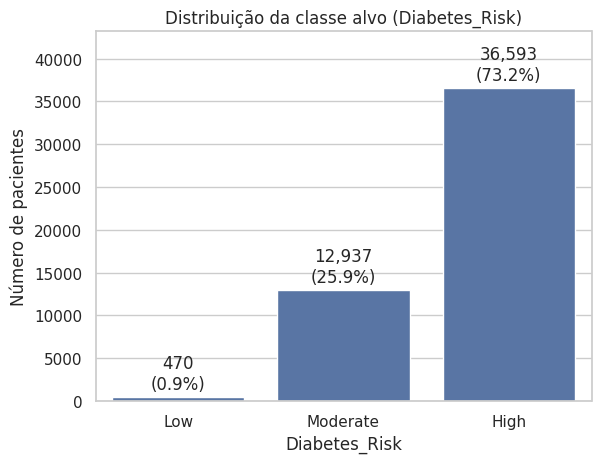

**Leitura automática:** a menor classe (`Low`) representa **0.9%** dos registros; a maior (`High`), **73.2%** (razão de 77.86 para 1).

In [11]:
def label_bars(ax, labels=None, fmt: str = "{:,.0f}") -> None:
    """Escreve o valor (ou um texto personalizado) acima de cada barra do gráfico."""
    for i, bar in enumerate(ax.patches):
        text = labels[i] if labels else fmt.format(bar.get_height())
        ax.annotate(text, (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha="center", va="bottom", xytext=(0, 3), textcoords="offset points")


def plot_target_distribution(labels: pd.Series) -> pd.Series:
    """Gráfico de barras da frequência das classes, com contagem e percentual."""
    counts = labels.value_counts().reindex(CLASS_LIST)
    ax = sns.barplot(x=counts.index, y=counts.values, color="#4C72B0")
    texts = [f"{n:,}\n({n / counts.sum():.1%})" for n in counts.values]
    label_bars(ax, texts)
    ax.set(title=f"Distribuição da classe alvo ({TARGET})", xlabel=TARGET,
           ylabel="Número de pacientes", ylim=(0, counts.max() * 1.18))
    plt.show()
    return counts


target_counts = plot_target_distribution(target_labels)
display(Markdown(
    f"**Leitura automática:** a menor classe (`{target_counts.idxmin()}`) representa "
    f"**{target_counts.min() / target_counts.sum():.1%}** dos registros; a maior (`{target_counts.idxmax()}`), "
    f"**{target_counts.max() / target_counts.sum():.1%}** (razão de {target_counts.max() / target_counts.min():.2f} para 1)."
))

### Análise do Gráfico 1 – Distribuição do risco

**O que o gráfico mostra:** quantos pacientes há em cada nível de risco.
- **High (alto):** 73,2% dos pacientes (cerca de 36.600).
- **Moderate (moderado):** 25,9% (cerca de 12.950).
- **Low (baixo):** só 0,9% (cerca de 470).

A maior classe é quase **78 vezes maior** que a menor. Os dados são, portanto, **muito desbalanceados**.

**Por que isso importa:**
- **A acurácia engana.** Um modelo que sempre respondesse "High" acertaria cerca de 73% sem aprender nada.
- **A classe `Low` é difícil de aprender.** Só haverá cerca de 375 exemplos dela no treino.
- Na modelagem, será preciso olhar o desempenho **de cada classe** (por exemplo, *recall* e F1 macro) e usar técnicas como `class_weight` ou *oversampling*, **somente no treino**.

**O que já fazemos agora:** a divisão entre treino e teste é *estratificada*, ou seja, mantém as mesmas proporções nos dois grupos (73,2% / 25,9% / 0,9%, confirmado na seção 4.3).

**Em uma frase:** a maioria dos pacientes é de alto risco e quase não há pacientes de baixo risco, o que exige cuidado na avaliação dos modelos.

### Gráfico 2 – Distribuição de cada atributo numérico
Histogramas com curva de densidade para cada variável contínua. Servem para identificar assimetrias, caudas longas e escalas diferentes, o que orienta as transformações do pré-processamento (padronização, normalização, discretização).

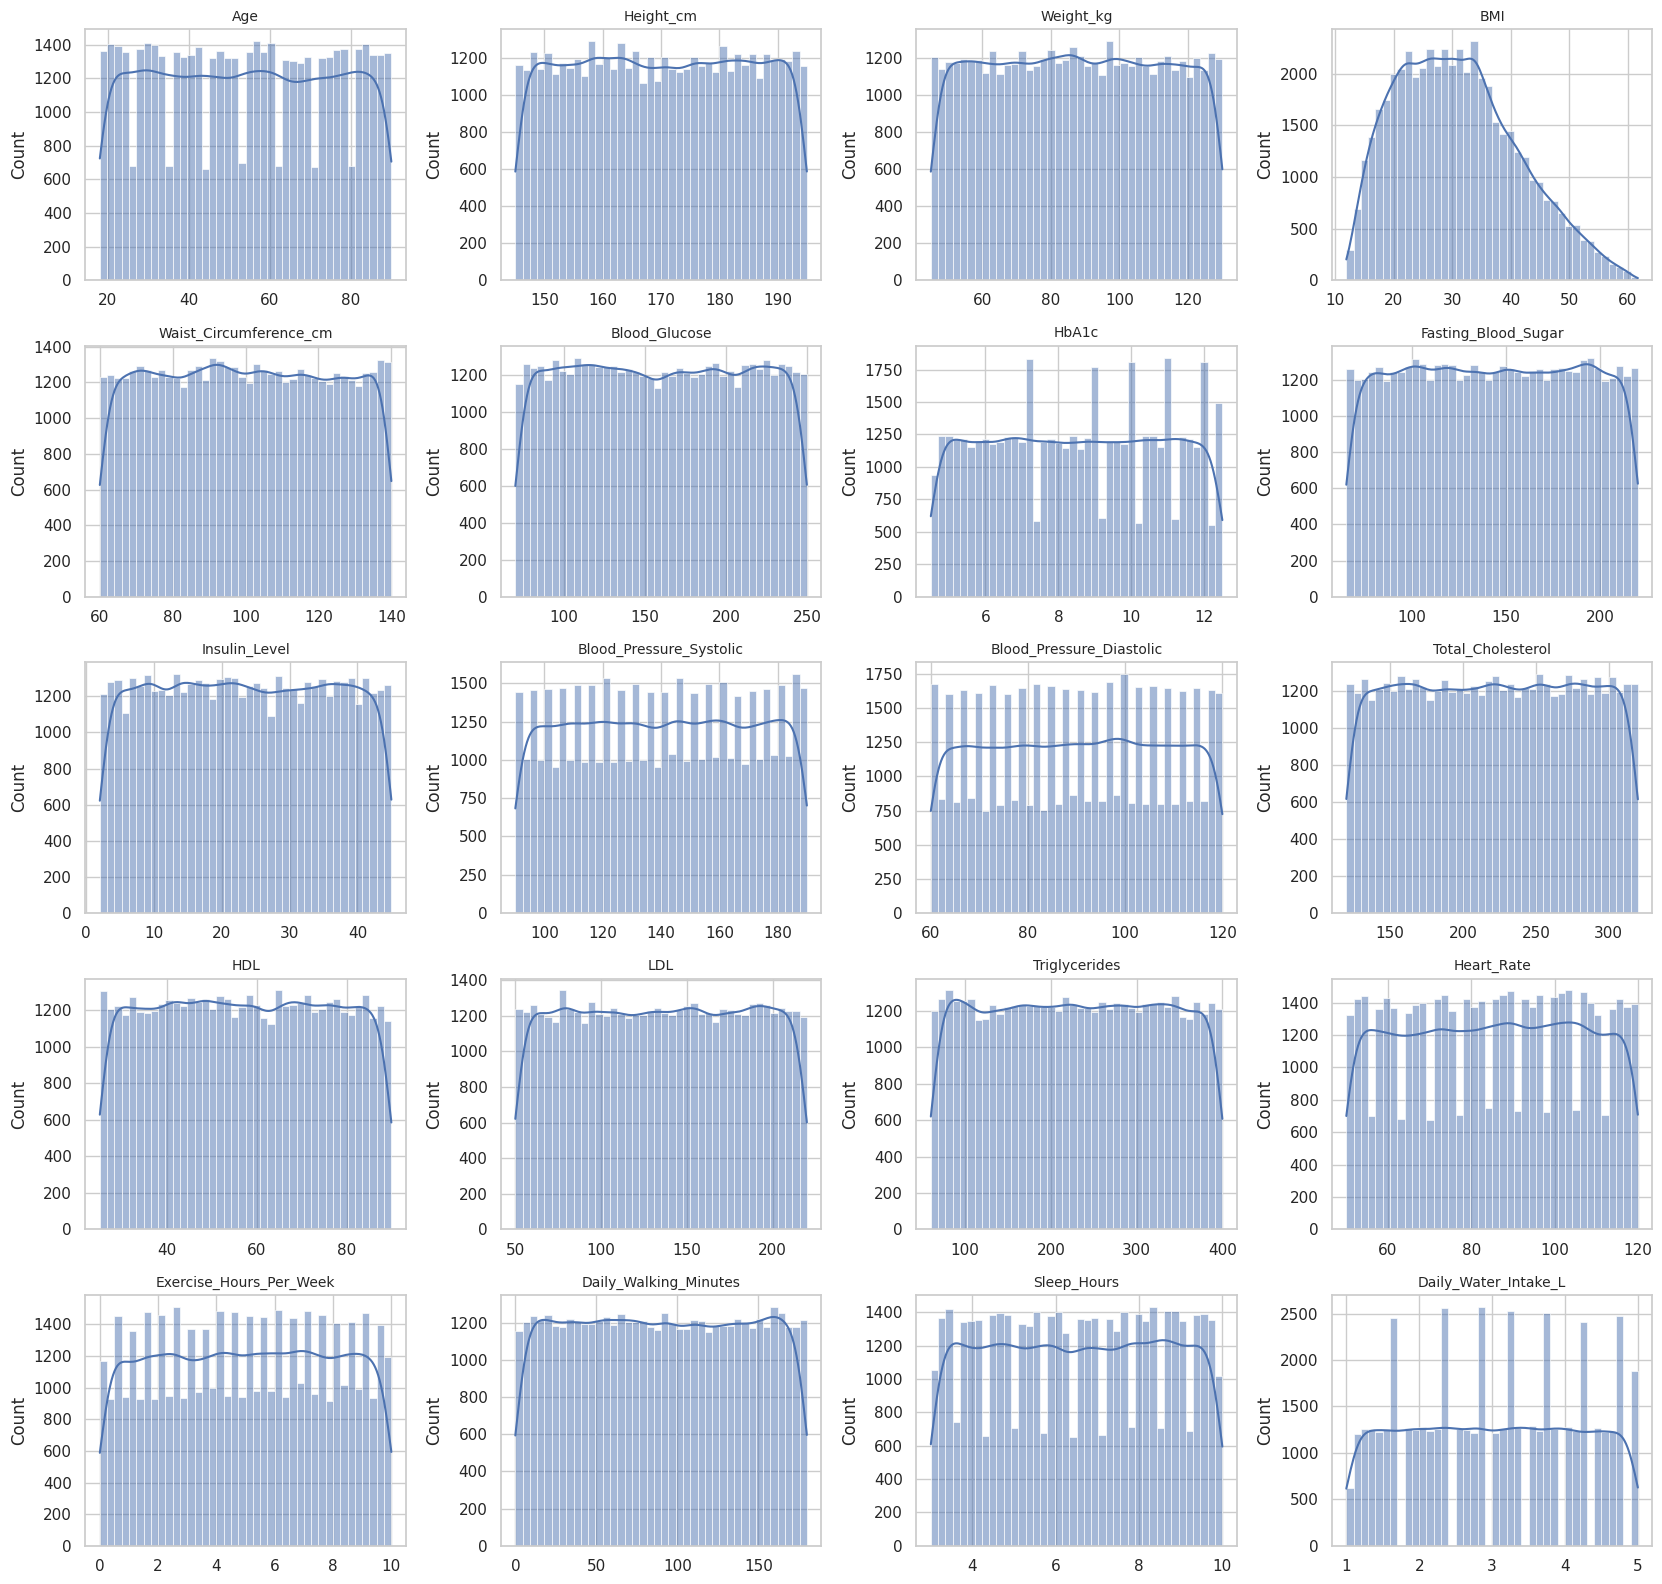

,assimetria
BMI,0.43
Age,0.01
Blood_Glucose,0.01
Waist_Circumference_cm,0.01
Total_Cholesterol,-0.01
Sleep_Hours,-0.01
Blood_Pressure_Diastolic,-0.01
Insulin_Level,0.01
Exercise_Hours_Per_Week,-0.01
Heart_Rate,-0.01


In [12]:
def plot_grid(columns, draw_fn, ncols: int = 4, cell_size=(4.2, 3.2)) -> None:
    """Cria uma grade de subgráficos e aplica draw_fn(coluna, eixo) em cada um."""
    nrows = math.ceil(len(columns) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(cell_size[0] * ncols, cell_size[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, col in zip(axes, columns):
        draw_fn(col, ax)
    for ax in axes[len(columns):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()


def draw_histogram(col, ax):
    sns.histplot(df[col], kde=True, bins=40, ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")


plot_grid(continuous_cols, draw_histogram)

skewness = df[continuous_cols].skew().round(2).rename("assimetria").to_frame()
display(skewness.sort_values("assimetria", key=abs, ascending=False))

### Análise do Gráfico 2 – Distribuição dos atributos numéricos

**O que o gráfico mostra:** para cada medida, quantos pacientes há em cada faixa de valores (histograma).

**O que percebemos:**
- Quase todos os histogramas são **retangulares**: os valores se espalham por igual entre o mínimo e o máximo. A tabela de assimetria confirma, com valores entre -0,01 e 0,01 (0 significa distribuição simétrica).
- Isso é **raro em dados reais**. Na vida real, idade, glicose e colesterol se concentram em torno de um valor típico (formato de sino). Mais um sinal de dados sintéticos.
- **Exceção: o `BMI`**, que tem formato assimétrico, com cauda longa para a direita (assimetria de 0,43). Isso acontece porque ele é calculado a partir de peso e altura.
- As "barras mais baixas ou mais altas" em `Age`, `HbA1c`, `Heart_Rate`, pressões e `Daily_Water_Intake_L` **não são problema nos dados**. Acontecem porque esses valores são inteiros ou arredondados e caem de forma irregular nas 40 faixas do gráfico.

**O que isso muda no pré-processamento:**
- Não precisamos de transformação logarítmica (a assimetria é baixa).
- As **escalas são muito diferentes** entre os atributos, então a **padronização** e a **normalização** fazem sentido.
- A **discretização** (dividir em faixas) é opcional, e foi gerada como visão extra.

**Em uma frase:** os atributos são quase todos uniformes, e o `BMI` é o único com formato diferente.

### Gráfico 3 – Distribuição dos atributos categóricos e binários
Gráficos de contagem para cada atributo categórico (até as `MAX_CATEGORIES_PLOT` categorias mais frequentes). Úteis para ver categorias raras e decidir o tipo de codificação.

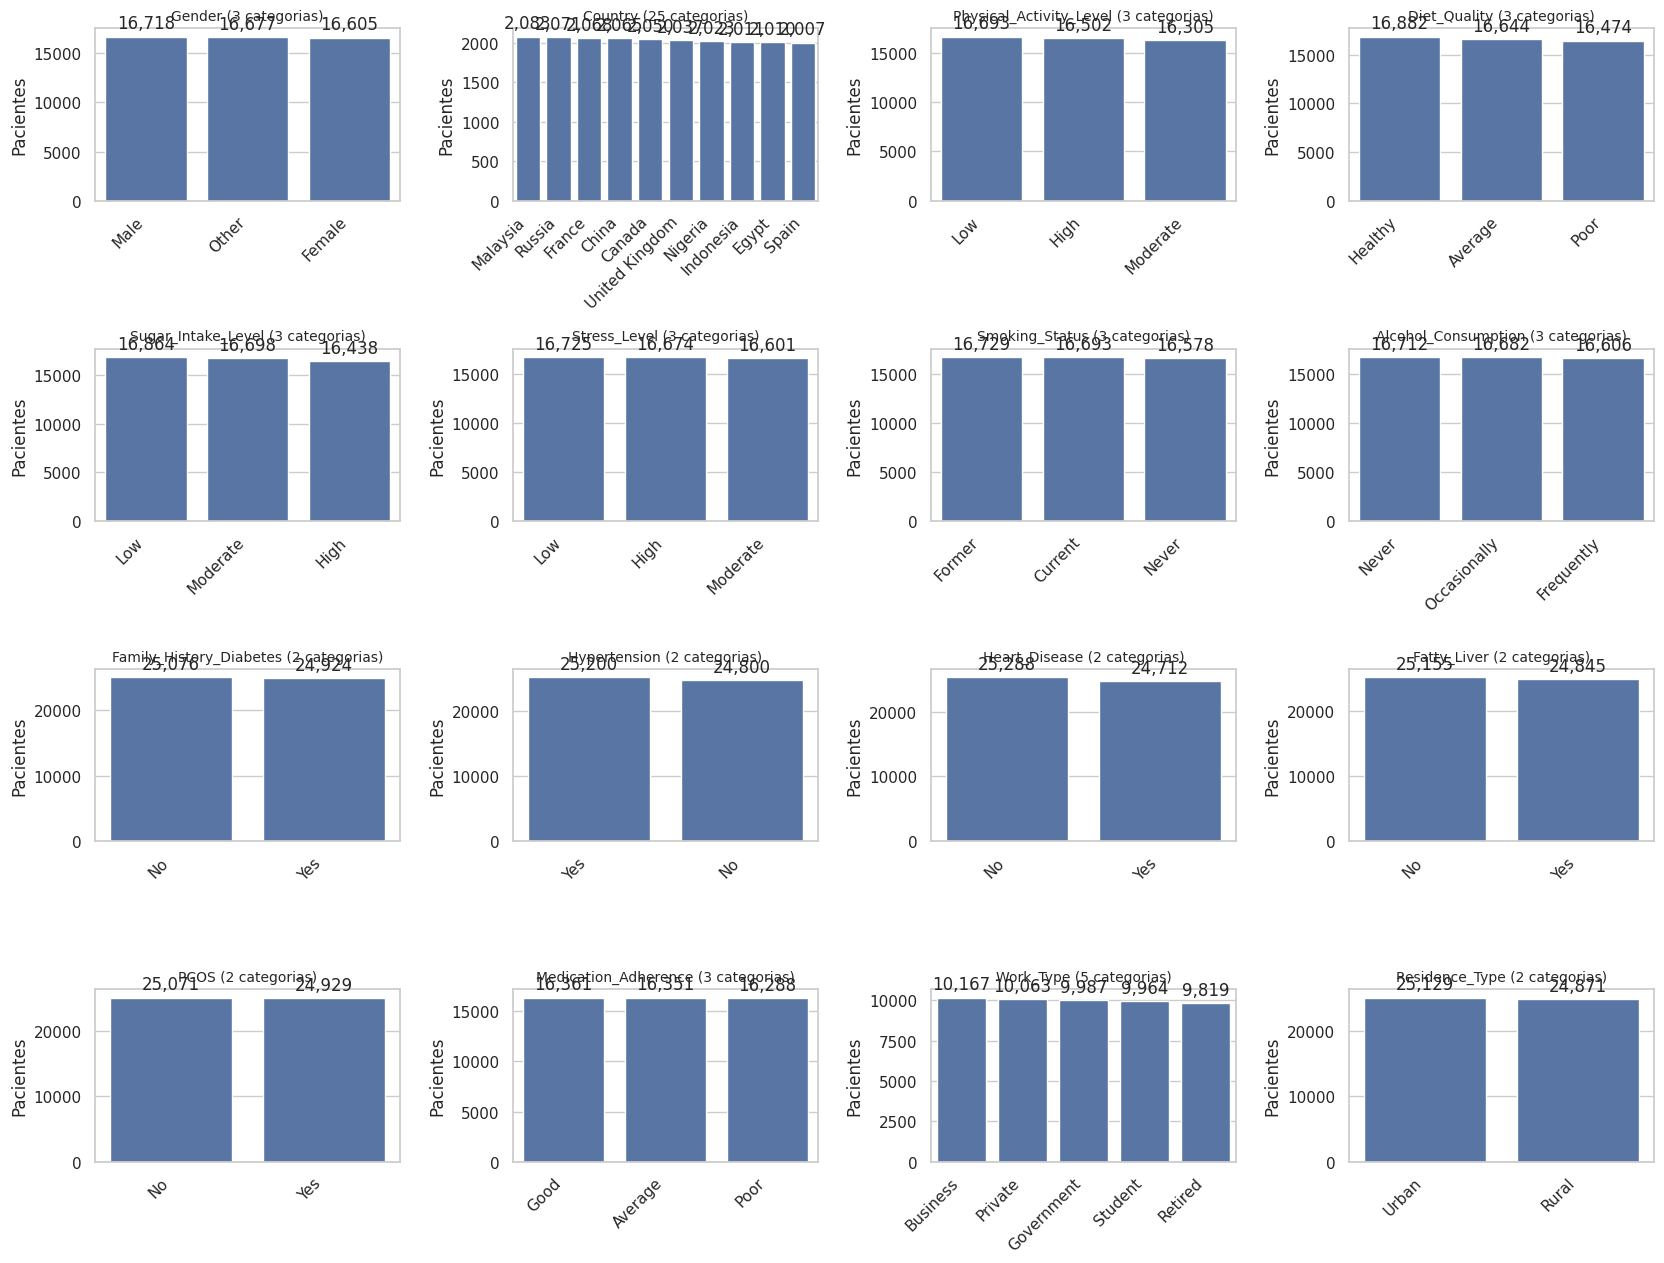

In [13]:
def draw_countplot(col, ax):
    order = df[col].value_counts().index[:MAX_CATEGORIES_PLOT]
    sns.countplot(data=df[df[col].isin(order)], x=col, order=order, color="#4C72B0", ax=ax)
    label_bars(ax)
    ax.set_title(f"{col} ({df[col].nunique()} categorias)", fontsize=10)
    ax.set(xlabel="", ylabel="Pacientes")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")


plot_grid(category_like_cols, draw_countplot)

### Análise do Gráfico 3 – Distribuição dos atributos categóricos

**O que o gráfico mostra:** quantos pacientes há em cada categoria de cada atributo de texto.

**O que percebemos:** tudo está **perfeitamente equilibrado**.
- Atributos com 3 níveis (como `Diet_Quality` ou `Smoking_Status`): cerca de 33% em cada nível. Isso inclui `Gender`, com `Other` em um terço dos registros.
- Atributos com 2 níveis (`Yes/No`, `Urban/Rural`): cerca de 50% para cada lado.
- `Work_Type`: cerca de 20% em cada uma das 5 categorias.
- `Country`: 25 países com cerca de 4% cada.

Não há categorias raras nem colunas constantes. Por isso, a regra de agrupar categorias com menos de 1% do pré-processamento não precisou agrupar nada.

**Tipos de variável categórica:**
- **Nominais** (sem ordem): `Gender`, `Country`, `Work_Type`, `Residence_Type` e `Smoking_Status`.
- **Ordinais** (com ordem natural, do pior para o melhor): `Physical_Activity_Level`, `Diet_Quality`, `Sugar_Intake_Level`, `Stress_Level`, `Alcohol_Consumption` e `Medication_Adherence`.

Usamos *one-hot encoding* (uma coluna 0/1 para cada categoria) em todas, porque é uma escolha neutra, que não inventa distâncias entre níveis. O custo é o número de colunas: só `Country` gera 24.

**Em uma frase:** as categorias são equilibradas, sem nenhuma rara, e todas serão transformadas em colunas 0/1.

### Gráfico 4 – Atributos numéricos × classe alvo
*Boxplots* comparam a distribuição de cada variável contínua entre as classes de risco. Se as caixas estiverem bem deslocadas, o atributo ajuda a separar as classes. Também aparecem os pontos fora do limite (outliers).

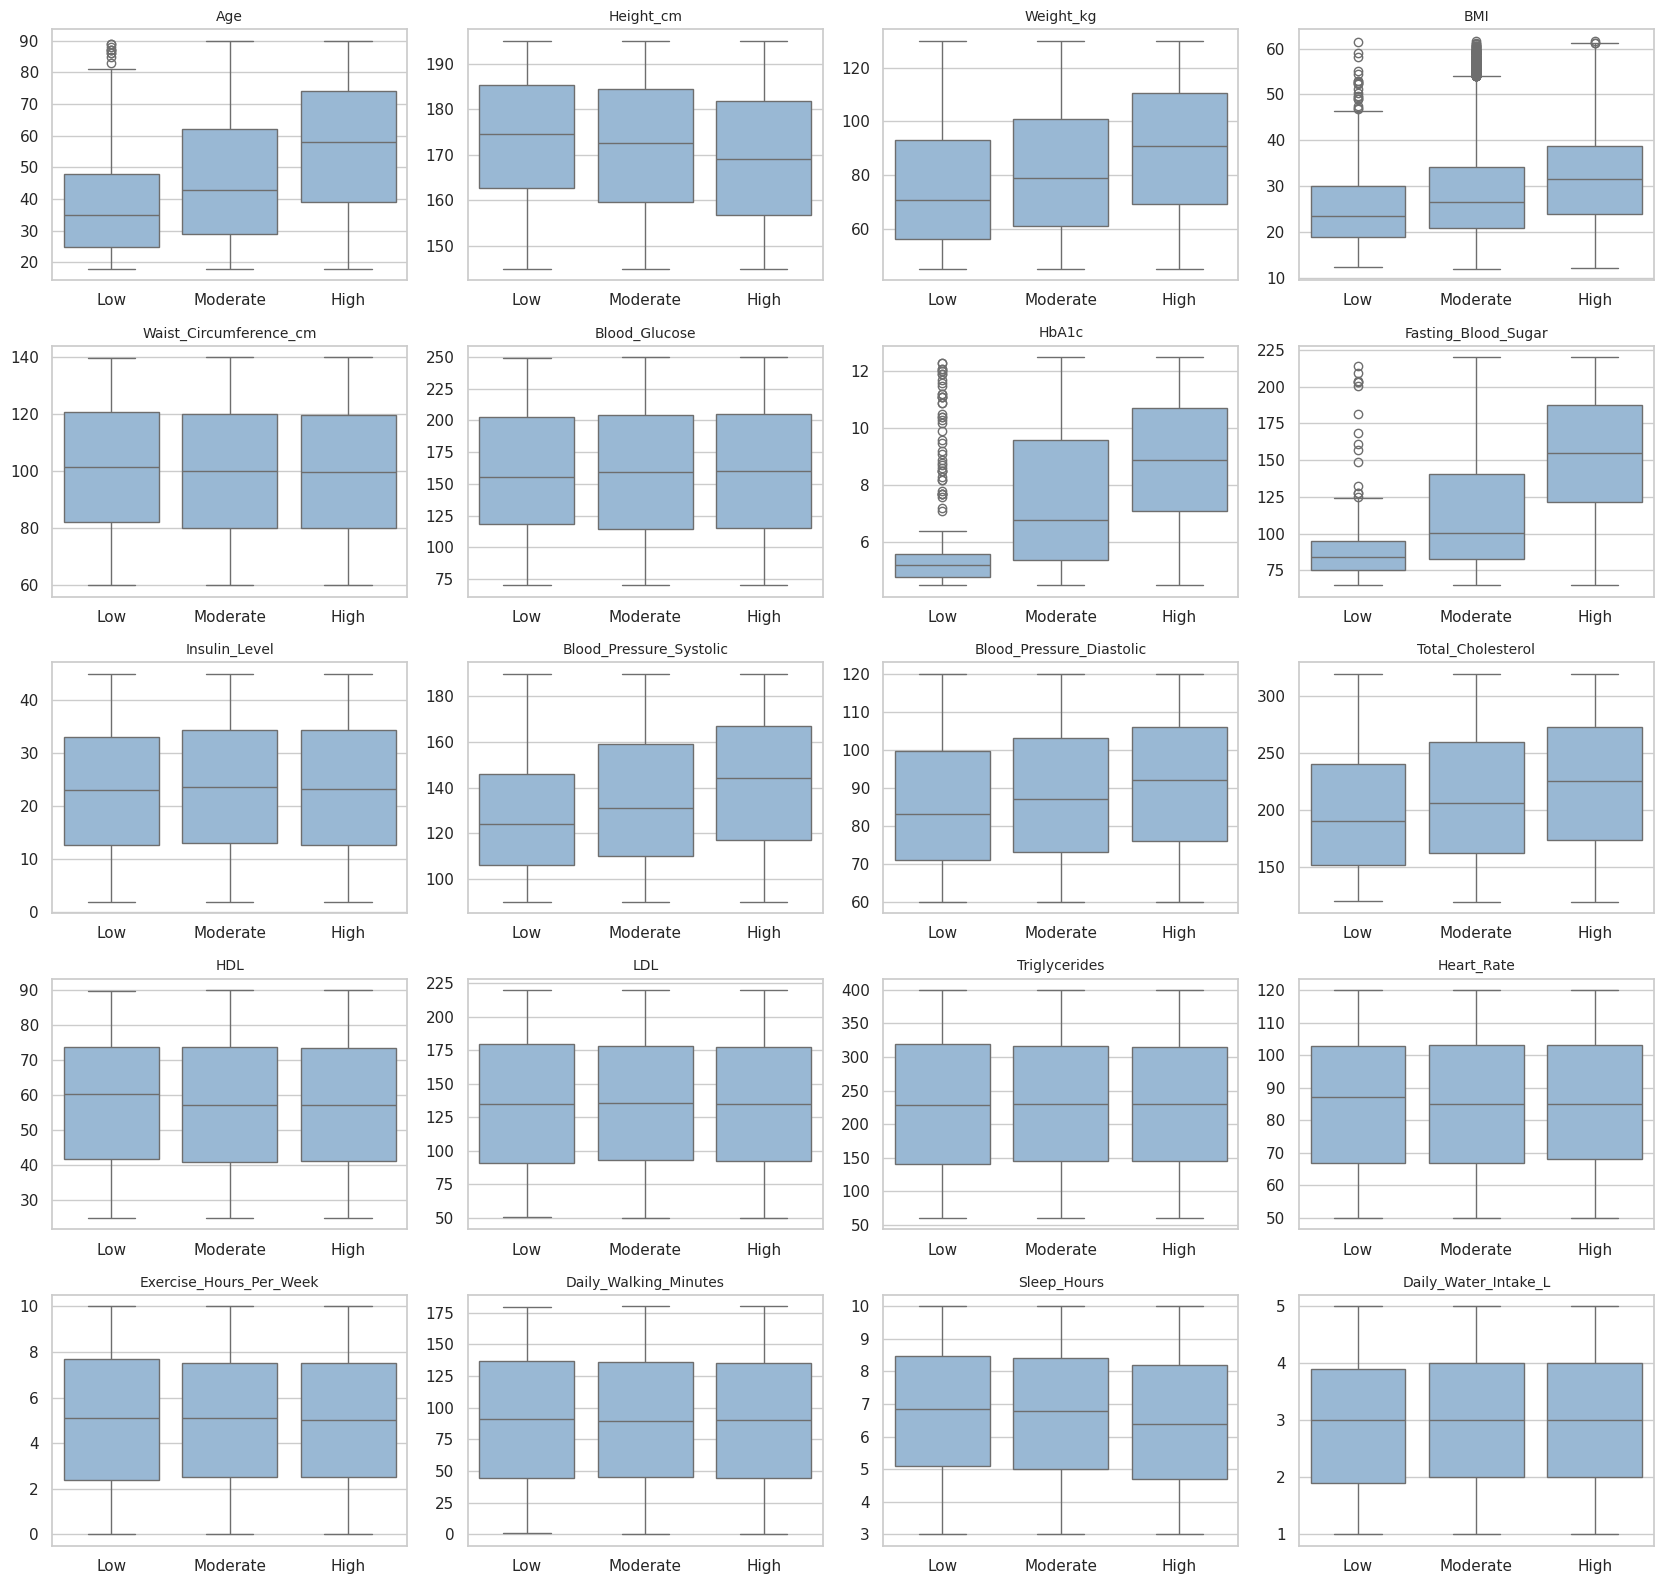

classe,Low,Moderate,High,variação Low -> High (%)
Fasting_Blood_Sugar,88.442,115.813,152.776,72.741
HbA1c,5.673,7.543,8.859,56.141
Age,38.813,46.891,56.527,45.638
BMI,25.597,28.306,31.918,24.693
Weight_kg,75.677,81.769,89.613,18.415
Total_Cholesterol,200.409,211.824,223.375,11.459
Blood_Pressure_Systolic,127.977,134.730,142.251,11.154
Blood_Pressure_Diastolic,85.549,88.058,90.797,6.134
Sleep_Hours,6.775,6.664,6.440,-4.953
Height_cm,173.663,171.758,169.354,-2.481


In [14]:
def draw_boxplot_by_target(col, ax):
    sns.boxplot(x=target_labels, y=df[col], order=CLASS_LIST, color="#8FB8DE", ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set(xlabel="", ylabel="")


plot_grid(continuous_cols, draw_boxplot_by_target)

group_means = df.groupby(target_labels)[continuous_cols].mean().reindex(CLASS_LIST).T
group_means[f"variação {CLASS_LIST[0]} -> {HIGH_CLASS} (%)"] = (
    (group_means[HIGH_CLASS] / group_means[CLASS_LIST[0]] - 1) * 100
)
display(group_means.round(3).sort_values(group_means.columns[-1], key=abs, ascending=False))

### Análise do Gráfico 4 – Atributos numéricos × nível de risco

**O que o gráfico mostra:** para cada medida, uma caixa (*boxplot*) por nível de risco. Se as caixas estão em alturas diferentes, aquela medida ajuda a distinguir os níveis. A tabela ao lado mostra a média por classe.

**Atributos que aumentam junto com o risco (Low < Moderate < High):**

| Atributo | Low | Moderate | High | Aumento de Low para High |
|---|---|---|---|---|
| `Fasting_Blood_Sugar` (glicemia de jejum) | 88,4 | 115,8 | 152,8 | +73% |
| `HbA1c` | 5,7 | 7,5 | 8,9 | +56% |
| `Age` (idade) | 38,8 | 46,9 | 56,5 | +46% |
| `BMI` | 25,6 | 28,3 | 31,9 | +25% |
| `Weight_kg` | 75,7 | 81,8 | 89,6 | +18% |
| `Total_Cholesterol` | 200,4 | 211,8 | 223,4 | +11% |
| `Blood_Pressure_Systolic` | 128,0 | 134,7 | 142,3 | +11% |
| `Blood_Pressure_Diastolic` | 85,5 | 88,1 | 90,8 | +6% |

**Atributos que praticamente não mudam entre as classes** (variação de no máximo 2,3%): `Blood_Glucose` (159,0 / 159,5 / 160,1), `Insulin_Level`, `Waist_Circumference_cm`, `LDL`, `HDL`, `Triglycerides`, `Heart_Rate`, `Exercise_Hours_Per_Week`, `Daily_Walking_Minutes` e `Daily_Water_Intake_L`. `Height_cm` (-2,5%) e `Sleep_Hours` (-5,0%) mostram só uma queda leve.

**Pontos de atenção:**
1. **As caixas se sobrepõem bastante.** Mesmo na glicemia de jejum, a diferença entre `Low` e `High` é de cerca de 64 mg/dL, contra um desvio-padrão (variação típica) de 45. Cada atributo sozinho separa as classes só em parte.
2. **`Blood_Glucose` não ajuda em nada**, ao contrário de `Fasting_Blood_Sugar` e `HbA1c`. Isso contraria a expectativa clínica, e deve ser mais uma característica dos dados sintéticos.
3. A classe `Low` tem poucos pacientes, então suas médias são menos estáveis.

**Em uma frase:** glicemia de jejum, HbA1c, idade e IMC são as medidas que mais mudam com o risco, mas nenhuma separa as classes sozinha.

### Gráfico 5 – Atributos categóricos × classe alvo
Para cada categoria, mostra a **proporção de pacientes na classe de maior risco**. A linha tracejada é a proporção geral. Barras bem acima ou abaixo da linha indicam categorias associadas a mais ou menos casos graves.

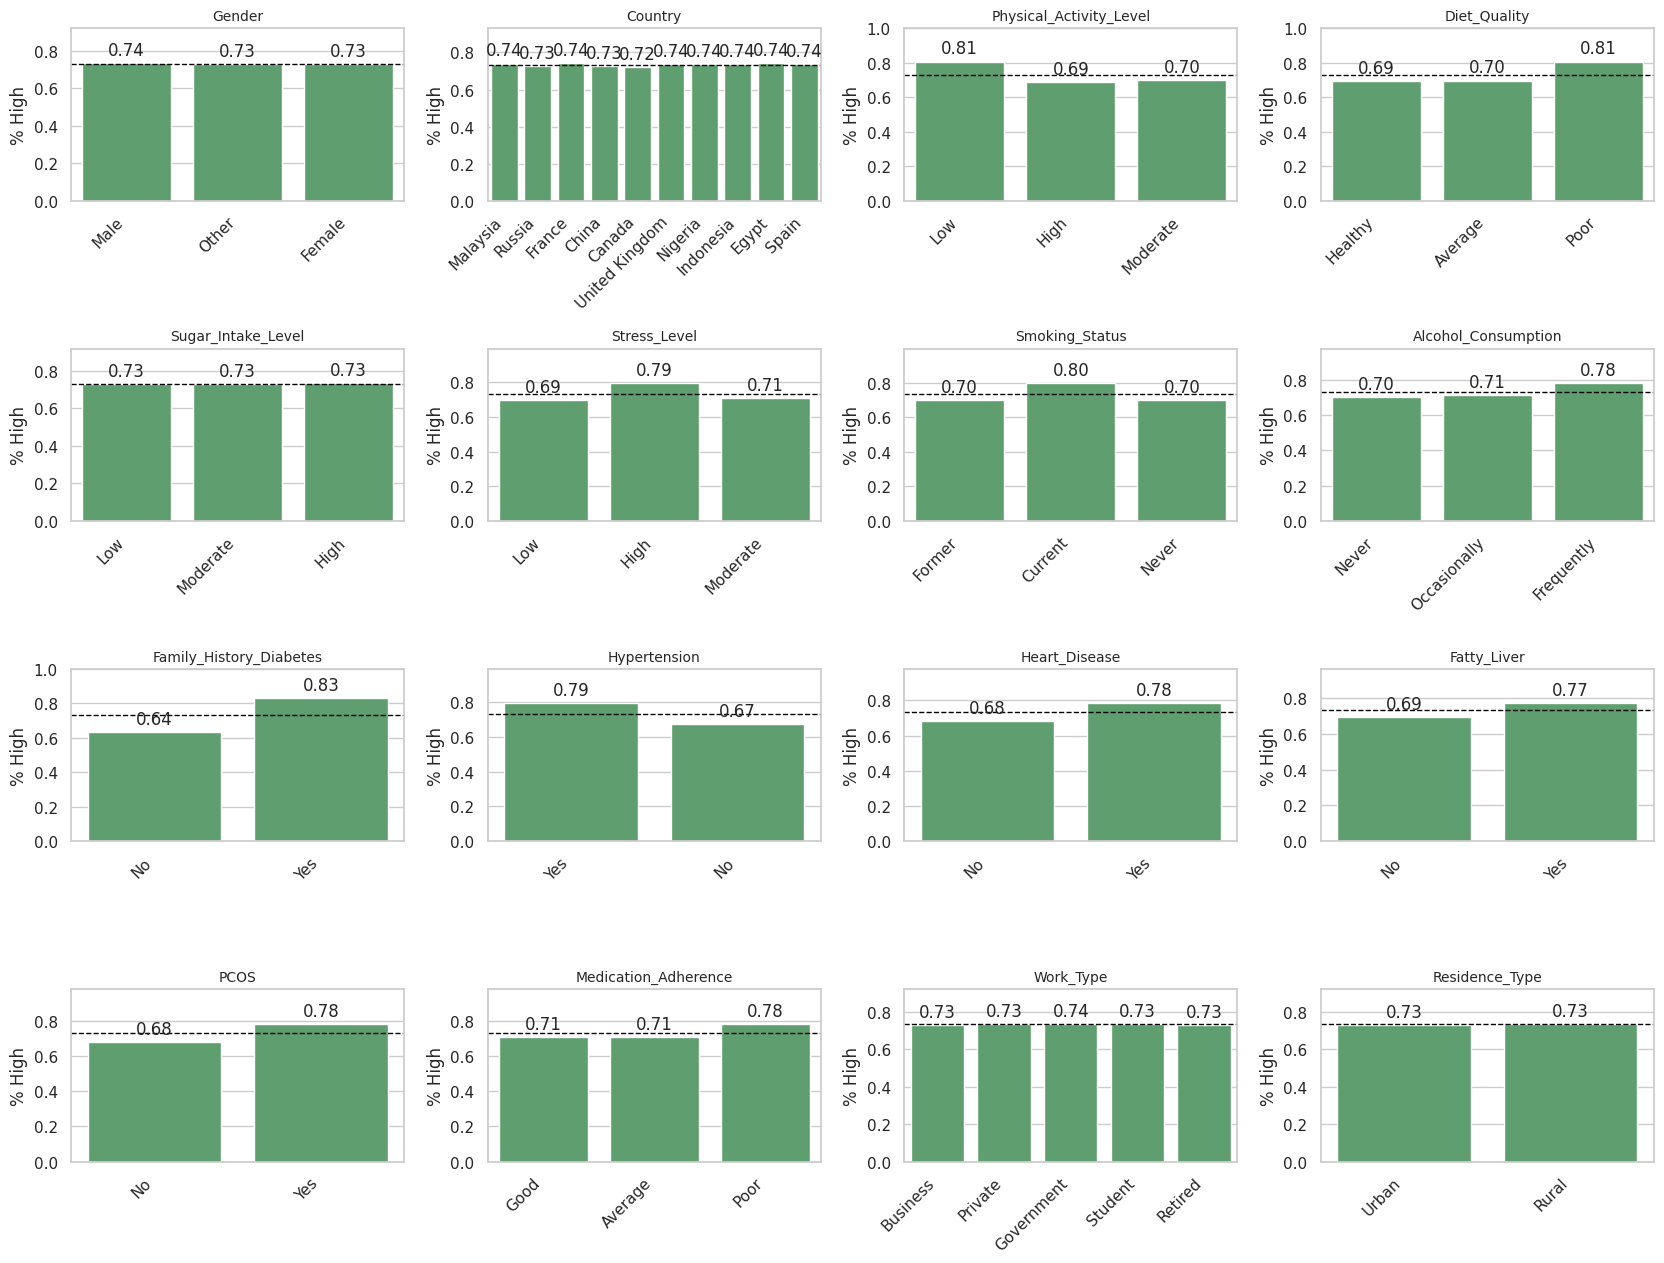

Proporção geral da classe 'High' = 0.732 (linha tracejada)


In [15]:
is_high_class = (df[TARGET] == N_CLASSES - 1)
overall_rate = is_high_class.mean()


def draw_rate_by_category(col, ax):
    top = df[col].value_counts().index[:MAX_CATEGORIES_PLOT]
    rates = is_high_class[df[col].isin(top)].groupby(df[col]).mean().reindex(top)
    sns.barplot(x=rates.index.astype(str), y=rates.values, color="#55A868", ax=ax)
    label_bars(ax, fmt="{:.2f}")
    ax.axhline(overall_rate, color="black", linestyle="--", linewidth=1)
    ax.set_title(col, fontsize=10)
    ax.set(xlabel="", ylabel=f"% {HIGH_CLASS}", ylim=(0, min(1, rates.max() * 1.25)))
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")


plot_grid(category_like_cols, draw_rate_by_category)
print(f"Proporção geral da classe '{HIGH_CLASS}' = {overall_rate:.3f} (linha tracejada)")

### Análise do Gráfico 5 – Atributos categóricos × nível de risco

**O que o gráfico mostra:** em cada categoria, qual a porcentagem de pacientes de risco `High`. A linha tracejada é a porcentagem geral (73,2%). Barras acima da linha indicam categorias com mais casos graves.

**Sem relação com o risco** (barras praticamente sobre a linha, diferenças de 1 ou 2 pontos): `Gender`, `Country`, `Sugar_Intake_Level`, `Work_Type` e `Residence_Type`.

**Associados a mais pacientes `High`** (p.p. = pontos percentuais de diferença):

| Atributo e categoria de maior risco | % de `High` | Comparação | Diferença |
|---|---|---|---|
| `Family_History_Diabetes` = Yes | 83% | 64% (No) | +19 p.p. |
| `Hypertension` = Yes | 79% | 67% (No) | +12 p.p. |
| `Physical_Activity_Level` = Low | 81% | 69–70% (High/Moderate) | +11 p.p. |
| `Diet_Quality` = Poor | 81% | 69–70% (Healthy/Average) | +11 a +12 p.p. |
| `Smoking_Status` = Current | 80% | 70% (Never/Former) | +10 p.p. |
| `Heart_Disease` = Yes | 78% | 68% (No) | +10 p.p. |
| `PCOS` = Yes | 78% | 68% (No) | +10 p.p. |
| `Stress_Level` = High | 79% | 69–71% (Low/Moderate) | +8 a +10 p.p. |
| `Fatty_Liver` = Yes | 77% | 69% (No) | +8 p.p. |
| `Alcohol_Consumption` = Frequently | 78% | 70–71% (Never/Occasionally) | +7 a +8 p.p. |
| `Medication_Adherence` = Poor | 78% | 71% (Good/Average) | +7 p.p. |

**Como ler:** nos atributos de três níveis, o aumento de risco aparece só no **pior nível**; os dois melhores níveis são parecidos entre si (por exemplo, atividade física: 81% de `High` no nível baixo, contra 69% e 70% nos níveis alto e moderado).

**Pontos de atenção:** os resultados seguem o que a medicina espera (histórico familiar, hipertensão e sedentarismo aumentam o risco), mas valem para este dataset sintético e **não provam causa e efeito**. Como cada fator pesa pouco, o modelo precisará **combiná-los**.

**Em uma frase:** 11 fatores de risco aumentam em 7 a 19 pontos a chance de risco alto, com destaque para o histórico familiar.

### Gráfico 6 – Correlação com o alvo e entre atributos
Mede a relação **linear** entre as variáveis numéricas e o alvo. Para alvo com mais de duas classes, as classes são tratadas como uma escala ordenada (`CLASS_ORDER`). Valores próximos de ±1 indicam relação forte; próximos de 0, ausência de relação linear. O mapa de calor mostra todas as variáveis numéricas; o gráfico de barras destaca as que mais se associam ao alvo.

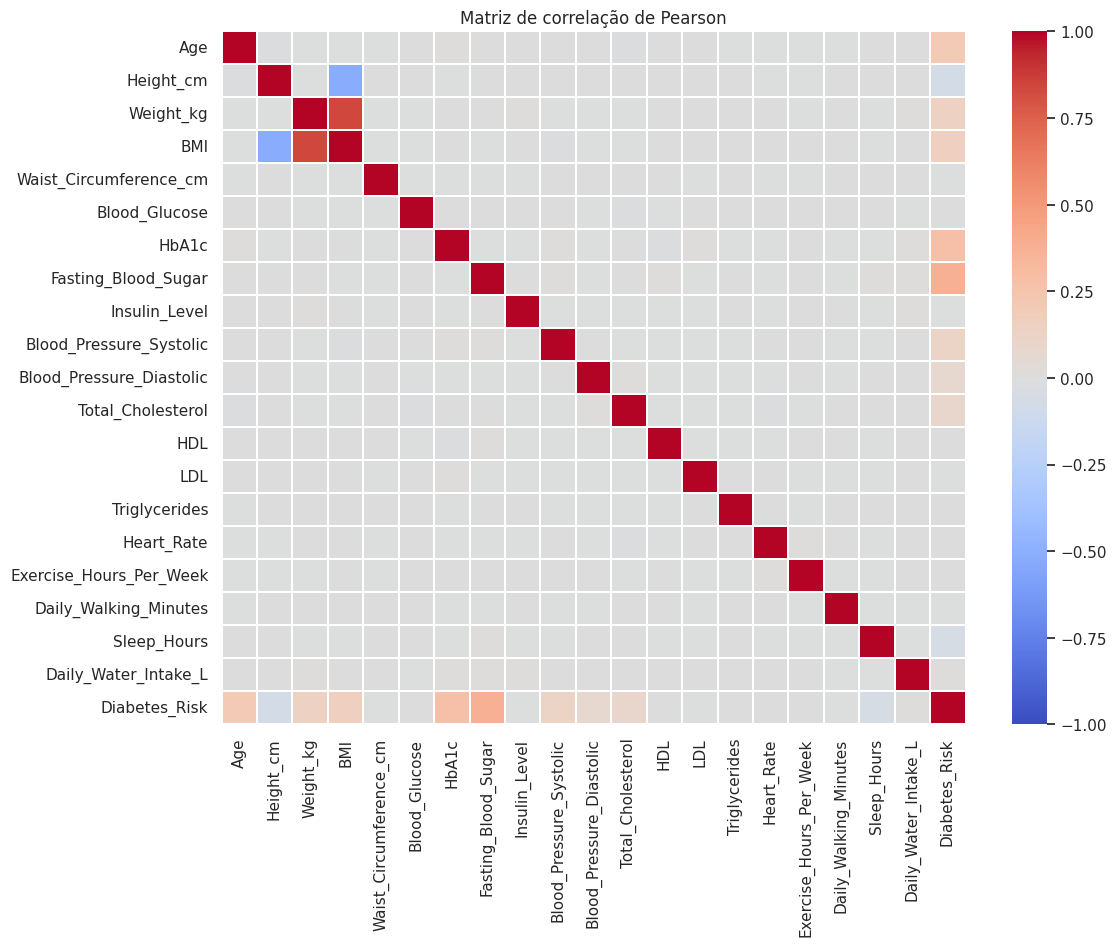

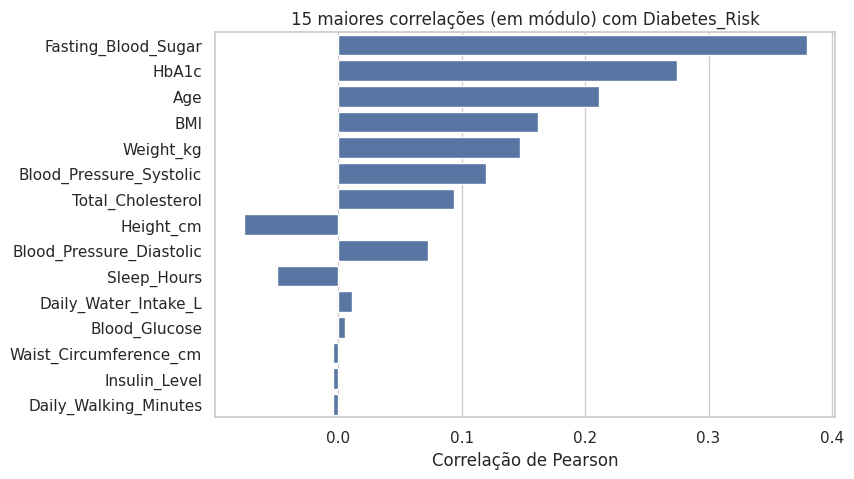

,correlação com o alvo,intensidade
Fasting_Blood_Sugar,0.380,moderada
HbA1c,0.275,fraca
Age,0.211,fraca
BMI,0.161,fraca
Weight_kg,0.147,fraca
Blood_Pressure_Systolic,0.120,fraca
Total_Cholesterol,0.094,desprezível
Height_cm,-0.077,desprezível
Blood_Pressure_Diastolic,0.073,desprezível
Sleep_Hours,-0.050,desprezível


**Pares de atributos com |correlação| ≥ 0,8:**

,atributo 1,atributo 2,correlação
37,Weight_kg,BMI,0.843


In [16]:
def describe_strength(r: float) -> str:
    """Traduz o coeficiente de correlação em uma classificação textual."""
    r = abs(r)
    if r < 0.10:
        return "desprezível"
    if r < 0.30:
        return "fraca"
    if r < 0.50:
        return "moderada"
    return "forte"


corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.2,
            annot=len(numeric_cols) <= 12, fmt=".2f")
plt.title("Matriz de correlação de Pearson")
plt.show()

target_corr = corr_matrix[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
top_corr = target_corr.head(15)
plt.figure(figsize=(8, 5))
sns.barplot(x=top_corr.values, y=top_corr.index, color="#4C72B0")
plt.title(f"15 maiores correlações (em módulo) com {TARGET}")
plt.xlabel("Correlação de Pearson")
plt.ylabel("")
plt.show()

ranking = pd.DataFrame({"correlação com o alvo": target_corr.round(3),
                        "intensidade": target_corr.map(describe_strength)})
display(ranking.head(15))

# Pares de atributos muito correlacionados entre si (possível multicolinearidade)
features_corr = corr_matrix.drop(index=TARGET, columns=TARGET)
upper = features_corr.where(np.triu(np.ones(features_corr.shape, dtype=bool), k=1))
pairs = upper.stack().rename("correlação").reset_index()
pairs.columns = ["atributo 1", "atributo 2", "correlação"]
strong_pairs = pairs[pairs["correlação"].abs() >= 0.8].sort_values("correlação", key=abs, ascending=False)
display(Markdown("**Pares de atributos com |correlação| ≥ 0,8:**"))
display(strong_pairs.round(3) if len(strong_pairs) else Markdown("Nenhum par encontrado."))

### Análise do Gráfico 6 – Correlações

**O que é correlação:** um número entre -1 e +1 que mede se duas variáveis "andam juntas". Perto de 0, não há relação linear; perto de +1, uma sobe quando a outra sobe; perto de -1, uma sobe quando a outra desce. Para o alvo, usamos a ordem Low (0) < Moderate (1) < High (2).

**Correlação com o nível de risco:**

| Atributo | Correlação | Intensidade |
|---|---|---|
| `Fasting_Blood_Sugar` | +0,38 | moderada |
| `HbA1c` | +0,28 | fraca |
| `Age` | +0,21 | fraca |
| `BMI` | +0,16 | fraca |
| `Weight_kg` | +0,15 | fraca |
| `Blood_Pressure_Systolic` | +0,12 | fraca |
| `Total_Cholesterol`, `Height_cm`, `Blood_Pressure_Diastolic`, `Sleep_Hours` | entre -0,08 e +0,09 | desprezível |
| `Blood_Glucose` e demais | próximas de 0 | nenhuma |

**O que percebemos:**
- **Nenhum atributo sozinho explica bem o risco.** A maior correlação é de 0,38 (moderada), o que reforça a necessidade de modelos que combinem várias variáveis.
- No mapa de calor, **quase tudo é cinza (correlação ≈ 0)**: os atributos não têm relação entre si. Em dados reais, é de esperar que glicose, HbA1c e glicemia de jejum andem juntas, mas aqui `Blood_Glucose` não se relaciona com nenhuma das duas. Mais um sinal de dados sintéticos.
- **As exceções envolvem o `BMI`**, que é calculado como peso ÷ altura². O único par com correlação acima de 0,8 é **`Weight_kg` × `BMI` (0,84)**, e `Height_cm` × `BMI` tem correlação negativa moderada (cerca de -0,5). Isso se chama **multicolinearidade** (variáveis repetindo a mesma informação). Em modelos lineares, convém manter só o `BMI` ou só peso e altura, ou usar regularização.

**Limitação:** a correlação de Pearson só enxerga relações em linha reta e, como `Low` tem pouquíssimos pacientes, o número reflete sobretudo a diferença entre `Moderate` e `High`.

**Em uma frase:** a glicemia de jejum é o atributo mais associado ao risco (0,38), e peso, altura e IMC se repetem entre si.

### Verificação das hipóteses com os dados
Resumo objetivo, calculado automaticamente, para apoiar a conclusão da seção 5.

In [17]:
def has(*columns) -> bool:
    return all(col in df.columns for col in columns)


lines = []
for col, label in [("Blood_Glucose", "H1"), ("Fasting_Blood_Sugar", "H1"), ("HbA1c", "H1"),
                   ("BMI", "H2"), ("Age", "H2"), ("Exercise_Hours_Per_Week", "H4")]:
    if has(col):
        means = df.groupby(target_labels)[col].mean().reindex(CLASS_LIST).round(2).to_dict()
        lines.append(f"- **{label} – {col}** (média por classe): {means}")

for col, label in [("Family_History_Diabetes", "H3"), ("Physical_Activity_Level", "H4")]:
    if has(col):
        rates = is_high_class.groupby(df[col]).mean().round(3).to_dict()
        lines.append(f"- **{label} – {col}** (proporção da classe '{HIGH_CLASS}' por categoria): {rates}")

display(Markdown("\n".join(lines)))

- **H1 – Blood_Glucose** (média por classe): {'Low': 159.01, 'Moderate': 159.46, 'High': 160.07}
- **H1 – Fasting_Blood_Sugar** (média por classe): {'Low': 88.44, 'Moderate': 115.81, 'High': 152.78}
- **H1 – HbA1c** (média por classe): {'Low': 5.67, 'Moderate': 7.54, 'High': 8.86}
- **H2 – BMI** (média por classe): {'Low': 25.6, 'Moderate': 28.31, 'High': 31.92}
- **H2 – Age** (média por classe): {'Low': 38.81, 'Moderate': 46.89, 'High': 56.53}
- **H4 – Exercise_Hours_Per_Week** (média por classe): {'Low': 5.03, 'Moderate': 5.02, 'High': 5.02}
- **H3 – Family_History_Diabetes** (proporção da classe 'High' por categoria): {'No': 0.635, 'Yes': 0.829}
- **H4 – Physical_Activity_Level** (proporção da classe 'High' por categoria): {'High': 0.69, 'Low': 0.807, 'Moderate': 0.697}

# 4. Pré-processamento de dados

**Objetivo:** limpar, tratar e transformar os dados, gerando **visões diferentes** do dataset prontas para modelos diversos.

## 4.1 Plano de operações e justificativas

| # | Operação | Justificativa |
|---|---|---|
| 1 | Remover `Patient_ID` e colunas derivadas do alvo (feito na seção 3.2) | Identificador não tem valor preditivo; colunas derivadas causam *data leakage* |
| 2 | Remover linhas duplicadas | Duplicatas inflam o peso de alguns pacientes e podem vazar entre treino e teste |
| 3 | Tratar valores ausentes (mediana para numéricos; moda para categóricos) | Os modelos do scikit-learn não aceitam `NaN`; a mediana é robusta a outliers. A imputação é ajustada **somente no treino** |
| 4 | Manter outliers e registros clinicamente inconsistentes | Os outliers (só `BMI`) são plausíveis; as inconsistências entre atributos (seção 3.1) não permitem saber qual valor está errado, e removê-las eliminaria muitos registros. Ficam registradas como limitação |
| 5 | Dividir em treino (80%) e teste (20%) **estratificado**, **antes** de qualquer transformação | Preserva a proporção das classes e evita *data leakage* do teste para o treino |
| 6 | Codificar categóricas com *one-hot* (categorias com menos de 1% dos dados agrupadas em "infrequente") | Evita impor ordem artificial a categorias nominais e controla o número de colunas em atributos com muitas categorias, como `Country` |
| 7 | Padronização (*z-score*) | Coloca atributos em escala comparável; indicada para regressão logística, SVM, redes neurais |
| 8 | Normalização (*min-max*) | Reescala para [0, 1]; indicada para algoritmos baseados em distância |
| 9 | Discretização em 5 faixas (quantis) | Reduz sensibilidade a outliers e permite modelos baseados em faixas |

## 4.2 Limpeza: duplicados

In [18]:
rows_before = len(df)
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Linhas removidas por duplicidade: {rows_before - len(df_clean):,}")
print(f"Linhas restantes: {len(df_clean):,}")

Linhas removidas por duplicidade: 0
Linhas restantes: 50,000


## 4.3 Divisão treino/teste (estratificada)
A divisão vem **primeiro**: os parâmetros de imputação, padronização, normalização e discretização serão aprendidos apenas com o conjunto de treino e depois aplicados ao teste, simulando a situação real em que o modelo recebe dados nunca vistos.

In [19]:
X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

print(f"Treino: {X_train.shape} | Teste: {X_test.shape}")
proportions = pd.DataFrame({"treino": y_train.map(CLASS_NAMES).value_counts(normalize=True),
                            "teste": y_test.map(CLASS_NAMES).value_counts(normalize=True)}).reindex(CLASS_LIST)
display(proportions.round(3))

Treino: (40000, 36) | Teste: (10000, 36)


,treino,teste
Diabetes_Risk,,
Low,0.009,0.009
Moderate,0.259,0.259
High,0.732,0.732


## 4.4 Construção das quatro visões do dataset
Cada visão é um `ColumnTransformer` do scikit-learn:

| Visão | Numéricas contínuas | Categóricas |
|---|---|---|
| `onehot` | imputação (mediana), **sem mudar a escala** | one-hot |
| `padronizado` | imputação + `StandardScaler` (média 0, desvio 1) | one-hot |
| `normalizado` | imputação + `MinMaxScaler` (intervalo [0, 1]) | one-hot |
| `discretizado` | imputação + `KBinsDiscretizer` (5 faixas por quantis, em one-hot) | one-hot |

Colunas binárias já numéricas (0/1) passam apenas pela imputação.

In [20]:
def build_preprocessor(view: str) -> ColumnTransformer:
    """Monta o pré-processador de uma das visões: onehot, padronizado, normalizado ou discretizado."""
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if view == "padronizado":
        numeric_steps.append(("scaler", StandardScaler()))
    elif view == "normalizado":
        numeric_steps.append(("scaler", MinMaxScaler()))
    elif view == "discretizado":
        numeric_steps.append(("bins", KBinsDiscretizer(n_bins=5, encode="onehot-dense",
                                                       strategy="quantile")))
    elif view != "onehot":
        raise ValueError(f"Visão desconhecida: {view}")

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(drop="if_binary", min_frequency=0.01,
                                 handle_unknown="infrequent_if_exist", sparse_output=False)),
    ])
    binary_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))])

    transformer = ColumnTransformer(
        transformers=[
            ("continuas", Pipeline(numeric_steps), continuous_cols),
            ("binarias", binary_pipeline, binary_cols),
            ("categoricas", categorical_pipeline, categorical_cols),
        ],
        verbose_feature_names_out=False,
    )
    return transformer.set_output(transform="pandas")


VIEWS = ["onehot", "padronizado", "normalizado", "discretizado"]
datasets = {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")      # avisos esperados do KBinsDiscretizer em colunas com poucos valores distintos
    for view in VIEWS:
        preprocessor = build_preprocessor(view)
        datasets[view] = {
            "train": preprocessor.fit_transform(X_train),   # aprende SOMENTE no treino
            "test": preprocessor.transform(X_test),         # apenas aplica no teste
        }
        print(f"{view:>13}: treino {datasets[view]['train'].shape} | teste {datasets[view]['test'].shape}")

       onehot: treino (40000, 80) | teste (10000, 80)
  padronizado: treino (40000, 80) | teste (10000, 80)
  normalizado: treino (40000, 80) | teste (10000, 80)
 discretizado: treino (40000, 160) | teste (10000, 160)


## 4.5 Verificação das transformações
Conferimos se cada transformação produziu o resultado esperado: média ≈ 0 e desvio ≈ 1 na visão padronizada, e mínimo 0 / máximo 1 na normalizada. **No conjunto de teste** esses valores podem ficar levemente fora do esperado, o que é normal: ele é transformado com os parâmetros do treino.

In [21]:
std_train = datasets["padronizado"]["train"][continuous_cols]
minmax_train = datasets["normalizado"]["train"][continuous_cols]

checks = pd.DataFrame({
    "padronizado: média": std_train.mean().round(4),
    "padronizado: desvio": std_train.std().round(4),
    "normalizado: mín": minmax_train.min().round(4),
    "normalizado: máx": minmax_train.max().round(4),
})
display(checks)

print("Valores ausentes após o pré-processamento (treino, todas as visões):",
      {view: int(data["train"].isna().sum().sum()) for view, data in datasets.items()})

,padronizado: média,padronizado: desvio,normalizado: mín,normalizado: máx
Age,-0.0,1.0,0.0,1.0
Height_cm,-0.0,1.0,0.0,1.0
Weight_kg,-0.0,1.0,0.0,1.0
BMI,0.0,1.0,0.0,1.0
Waist_Circumference_cm,0.0,1.0,0.0,1.0
Blood_Glucose,0.0,1.0,0.0,1.0
HbA1c,-0.0,1.0,0.0,1.0
Fasting_Blood_Sugar,-0.0,1.0,0.0,1.0
Insulin_Level,0.0,1.0,0.0,1.0
Blood_Pressure_Systolic,-0.0,1.0,0.0,1.0


Valores ausentes após o pré-processamento (treino, todas as visões): {'onehot': 0, 'padronizado': 0, 'normalizado': 0, 'discretizado': 0}


## 4.6 Salvando as visões em arquivos
Cada visão é salva (treino e teste, já com a coluna alvo) em CSV compactado (`.csv.gz`), que o `pandas` lê normalmente com `pd.read_csv`. A compactação mantém os arquivos abaixo do limite de tamanho do GitHub. Envie a pasta ao repositório junto com o notebook.

In [22]:
OUTPUT_DIR.mkdir(exist_ok=True)

saved_files = []
for view, parts in datasets.items():
    for split_name, target_values in [("train", y_train), ("test", y_test)]:
        table = parts[split_name].assign(**{TARGET: target_values.to_numpy()})
        path = OUTPUT_DIR / f"diabetes_{view}_{split_name}.csv.gz"
        table.to_csv(path, index=False, float_format="%.6g")
        saved_files.append({"arquivo": str(path), "linhas": table.shape[0],
                            "colunas": table.shape[1], "tamanho (MB)": round(path.stat().st_size / 1e6, 1)})

display(pd.DataFrame(saved_files))

,arquivo,linhas,colunas,tamanho (MB)
0,dados_processados/diabetes_onehot_train.csv.gz,40000,81,1.9
1,dados_processados/diabetes_onehot_test.csv.gz,10000,81,0.5
2,dados_processados/diabetes_padronizado_train.c...,40000,81,3.1
3,dados_processados/diabetes_padronizado_test.cs...,10000,81,0.8
4,dados_processados/diabetes_normalizado_train.c...,40000,81,2.3
5,dados_processados/diabetes_normalizado_test.cs...,10000,81,0.6
6,dados_processados/diabetes_discretizado_train....,40000,161,0.8
7,dados_processados/diabetes_discretizado_test.c...,10000,161,0.2


## 4.7 Retorno à análise exploratória com os dados pré-processados
Comparamos a escala original com a padronizada e verificamos quais atributos (incluindo as colunas criadas pelo *one-hot*) mais se associam ao alvo.

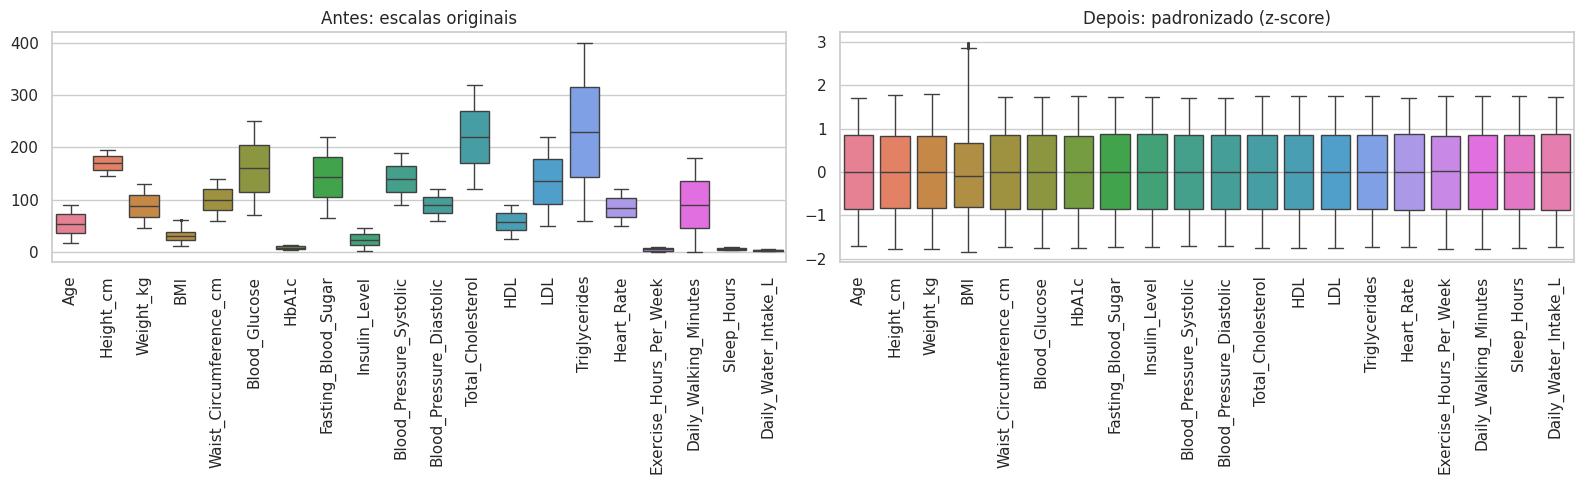

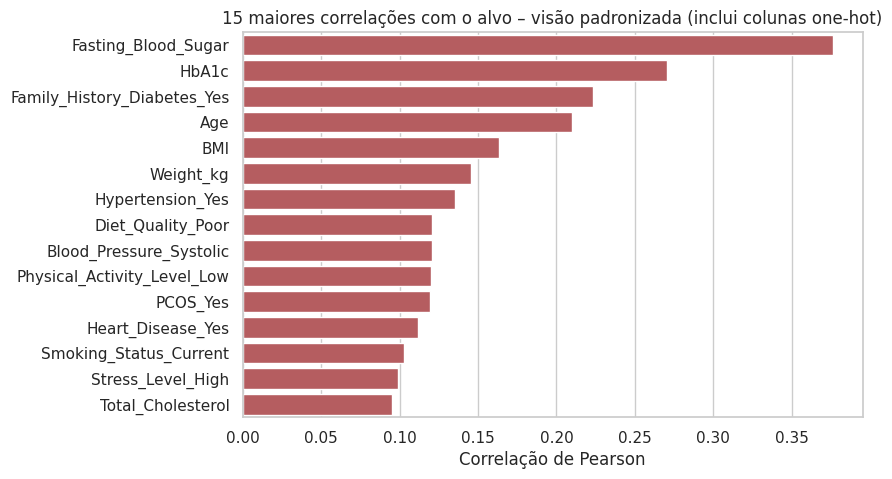

In [23]:
processed_train = datasets["padronizado"]["train"].assign(**{TARGET: y_train.to_numpy()})

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=X_train[continuous_cols], ax=axes[0], fliersize=1)
axes[0].set_title("Antes: escalas originais")
sns.boxplot(data=processed_train[continuous_cols], ax=axes[1], fliersize=1)
axes[1].set_title("Depois: padronizado (z-score)")
for ax in axes:
    ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()

processed_corr = processed_train.corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).head(15)
plt.figure(figsize=(8, 5))
sns.barplot(x=processed_corr.values, y=processed_corr.index, color="#C44E52")
plt.title("15 maiores correlações com o alvo – visão padronizada (inclui colunas one-hot)")
plt.xlabel("Correlação de Pearson")
plt.ylabel("")
plt.show()

### Análise após o pré-processamento

**Boxplots antes e depois da padronização:**
- *Antes*, as escalas variam de cerca de 1 (água) até 400 (triglicerídeos), impossível comparar as caixas.
- *Depois*, todas ficam centradas em zero e com a mesma amplitude (de aproximadamente -1,7 a +1,7), como esperado para dados uniformes. Isso foi confirmado na seção 4.5 (média 0 e desvio 1 no treino).
- A padronização **muda a escala, mas não o formato**: o `BMI` continua com valores extremos (até cerca de +3 desvios), mantidos de propósito.

**Ranking de correlação com o alvo (agora incluindo as colunas 0/1 criadas pelo *one-hot*):**
- `Fasting_Blood_Sugar` (≈ 0,38) e `HbA1c` (≈ 0,27) seguem no topo.
- **Novidade: `Family_History_Diabetes_Yes` aparece em 3º lugar (≈ 0,22)**, à frente de `Age` e `BMI`. Esse achado não aparecia antes, porque a matriz da seção 3.3 só tinha atributos numéricos.
- Logo depois vêm `Hypertension_Yes` (≈ 0,14) e as categorias de pior nível (`Diet_Quality_Poor`, `Physical_Activity_Level_Low`, `PCOS_Yes`, `Heart_Disease_Yes`, `Smoking_Status_Current`, `Stress_Level_High`), todas entre 0,10 e 0,12.

**Resultado final:** nenhum valor em branco em nenhuma das visões; 80 colunas nas visões `onehot`, `padronizado` e `normalizado` e 160 na `discretizado`.

**Em uma frase:** depois de transformar as categorias em números, o histórico familiar se mostra um dos atributos mais importantes para o risco.

# 5. Conclusões

### 5.1 O que descobrimos sobre cada hipótese

| Hipótese | Resultado | Evidência |
|---|---|---|
| **H1** – glicose e HbA1c mais altas em risco maior | **Parcialmente confirmada** | `Fasting_Blood_Sugar` sobe de 88 para 116 e para 153, e `HbA1c` de 5,7 para 7,5 e para 8,9 (correlações de cerca de 0,38 e 0,28). Mas `Blood_Glucose` fica em 159–160 nas três classes e **não** diferencia o risco. |
| **H2** – IMC e idade maiores em risco maior | **Confirmada (efeito fraco)** | `BMI`: 25,6 → 28,3 → 31,9; `Age`: 38,8 → 46,9 → 56,5 anos (correlações de cerca de 0,16 e 0,21). |
| **H3** – histórico familiar aumenta o risco | **Confirmada** | 83% dos pacientes com histórico familiar são de risco `High`, contra 64% dos demais. É o 3º atributo mais associado ao risco (correlação de cerca de 0,22). |
| **H4** – mais atividade física, menor risco | **Parcialmente confirmada** | Atividade baixa tem 81% de `High`, contra 69% e 70% nos outros níveis (cerca de 11 p.p. a mais). Mas atividade moderada e alta são parecidas, e `Exercise_Hours_Per_Week` (5,02 a 5,03 h) e `Daily_Walking_Minutes` (cerca de 90 min) não diferem entre as classes. |

### 5.2 Pontos de atenção
1. **Os dados são sintéticos:** quase todos os atributos são uniformes e independentes entre si, e há contradições clínicas (por exemplo, pressão diastólica maior que a sistólica). Os padrões refletem a geração dos dados, e não a realidade.
2. **Classes muito desbalanceadas:** `High` 73,2%, `Moderate` 25,9% e `Low` 0,9%. Na modelagem, usar métricas por classe, validação estratificada e `class_weight` ou *oversampling* apenas no treino.
3. **Vazamento de dados evitado:** removemos `Diabetes_Risk_Score` (o alvo é essa pontuação em faixas), `AI_Health_Recommendation`, `Doctor_Consultation_Needed` e `Patient_ID`.
4. **Variáveis repetidas:** `Weight_kg`, `Height_cm` e `BMI` carregam a mesma informação.
5. **Valores em branco:** 14 colunas com 1% a 6%, preenchidas com a mediana (numéricas) ou a moda (categóricas), aprendidas só com os dados de treino.
6. **Outliers:** só o `BMI` tem (0,06%), e foram mantidos de propósito.
7. **Poder de previsão limitado por atributo:** a maior correlação com o alvo é de cerca de 0,38.

### 5.3 O que foi entregue no pré-processamento
Dados divididos em **40.000 linhas de treino e 10.000 de teste** (estratificados), sem valores em branco, em **quatro versões** salvas na pasta `dados_processados/`:
- `onehot` (categorias em colunas 0/1, escala original), `padronizado` e `normalizado`, com 80 colunas cada;
- `discretizado` (valores em 5 faixas), com 160 colunas;

Todas incluem o alvo.

### 5.4 Próximos passos (fora do escopo deste MVP)
Treinar modelos de classificação com três classes (regressão logística, árvores, *random forest*, *gradient boosting*) usando as versões salvas, avaliar com F1 macro, *recall* por classe e matriz de confusão, e validar com validação cruzada estratificada.